# EasyVisa Project

## Context:

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

## Objective:

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired your firm EasyVisa for data-driven solutions. You as a data scientist have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.


## Data Description

The data contains the different attributes of the employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Importing necessary libraries and data

In [223]:
# Installing the libraries with the specified version.
!pip install numpy==1.25.2 pandas==1.5.3 scikit-learn==1.2.2 matplotlib==3.7.1 seaborn==0.13.1 xgboost==2.0.3

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [224]:
import warnings

warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Library to split data
from sklearn.model_selection import train_test_split

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier,
)

from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Libraries to get different metric scores
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# To tune different models
from sklearn.model_selection import GridSearchCV

##Importing Data Set

In [225]:
visa = pd.read_csv("data/EasyVisa.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [226]:
#make a copy of the data to preserve the original data set
data =visa.copy()

## Data Overview

- Observations
- Sanity checks

###View the first and last 5 rows of the data set

In [227]:
data.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [228]:
data.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.91,Year,Y,Certified


###Shape of the Data set

In [229]:
data.shape

(25480, 12)

- There are 25,480 rows and 12 columns in the data set.

###Check the Data types and Sanity Checks

In [230]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


- The dependent variable is case_status which is categorized as an 'object' meaning its categorical in nature.

The independent variables in the data set are composed of 3 types of data:
- 1 variable with 'float' data type -- prevailing_wage.
- 2 variables with 'integer' data type -- no_of_employees, yr_of_estab.
- 8 variables with 'object' data type (excluding the dependent variable case_status whichi is the 9th 'object' variable) -- case_id, continent, education_of_employee, has_job_experience, requires_job_training, region_of_employment, unit_of_wage, full_time_position.

There don't seem to be any missing values in the data set.

**Check for Duplicates**

In [231]:
data.duplicated().sum()

0

There are no duplicates in the data set.

**Check for Missing Values**

In [232]:
data.isnull().sum()

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64

In [233]:
data.isna().sum()

case_id                  0
continent                0
education_of_employee    0
has_job_experience       0
requires_job_training    0
no_of_employees          0
yr_of_estab              0
region_of_employment     0
prevailing_wage          0
unit_of_wage             0
full_time_position       0
case_status              0
dtype: int64

- There are no missing values in the data set.

**Dropping case_id since it will no longer be necessary**

In [234]:
#double checking to be sure that all values in case_id are unique
data.case_id.nunique()

25480

In [235]:
#dropping case_id and checking to see that the column was dropp successfully
data=data.drop('case_id', axis=1)
data.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


###Statistical Summary of the Data

In [236]:
#statistical summary of numerical variables
data.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.0,5667.043210,22877.928848,-26.0000,1022.00,2109.00,3504.0000,602069.00
yr_of_estab,25480.0,1979.409929,42.366929,1800.0000,1976.00,1997.00,2005.0000,2016.00
prevailing_wage,25480.0,74455.814592,52815.942327,2.1367,34015.48,70308.21,107735.5125,319210.27


- Firstly, we will need to take a look at no_of_employees since the minimum value is -26 which is not possible, we will explore to see what is going on here.
- The range of yr_of_estab is from 1800 to 2016 with the average being 1979 and median being 1997.
- prevailing wage has an average of 74455.81 and meadian of 70308.21 with a range from min 2.1367 to max 319210.27.
  - The minimimum of 2.1367 seems to be low but we'll look into this as well.


In [237]:
#locate the columns with a negative no_of_employees
data.loc[data['no_of_employees']<0]

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
245,Europe,Master's,N,N,-25,1980,Northeast,39452.9900,Year,Y,Certified
378,Asia,Bachelor's,N,Y,-11,2011,Northeast,32506.1400,Year,Y,Denied
832,South America,Master's,Y,N,-17,2002,South,129701.9400,Year,Y,Certified
2918,Asia,Master's,Y,N,-26,2005,Midwest,112799.4600,Year,Y,Certified
6439,Asia,Bachelor's,N,N,-14,2013,South,103.9700,Hour,Y,Denied
6634,Asia,Bachelor's,Y,N,-26,1923,West,5247.3200,Year,Y,Denied
7224,Europe,Doctorate,N,N,-25,1998,Midwest,141435.9500,Year,Y,Certified
7281,Asia,High School,N,N,-14,2000,Midwest,58488.5000,Year,Y,Denied
7318,Asia,Bachelor's,Y,Y,-26,2006,South,115005.6100,Year,Y,Certified
7761,Asia,Master's,N,N,-11,2009,Midwest,38457.5100,Year,Y,Certified


In [238]:
len(data.loc[data['no_of_employees']<0])

33

- There are 33 rows with a negative no_of_employees.
- We can assume this to be false, with the error likely being input.

We will fix this usng absolute value to take care of the negative numbers.

In [239]:
#Converting the negative values in no_of_employees to positive using absolute value
data['no_of_employees'] = np.abs(data['no_of_employees'])

#check to see the conversion worked correctly by looking for the minimum
data['no_of_employees'].min()

11

- The minimum value of no_of_emplyoees is now 11 meaning we have treated the negative values.

In [240]:
#checking low values for prevailing wage
data.loc[data['prevailing_wage']< 100]

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
338,Asia,Bachelor's,Y,N,2114,2012,Northeast,15.7716,Hour,Y,Certified
634,Asia,Master's,N,N,834,1977,Northeast,3.3188,Hour,Y,Denied
839,Asia,High School,Y,N,4537,1999,West,61.1329,Hour,Y,Denied
876,South America,Bachelor's,Y,N,731,2004,Northeast,82.0029,Hour,Y,Denied
995,Asia,Master's,N,N,302,2000,South,47.4872,Hour,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...
25023,Asia,Bachelor's,N,Y,3200,1994,South,94.1546,Hour,Y,Denied
25258,Asia,Bachelor's,Y,N,3659,1997,South,79.1099,Hour,Y,Denied
25308,North America,Master's,N,N,82953,1977,Northeast,42.7705,Hour,Y,Denied
25329,Africa,Bachelor's,N,N,2172,1993,Northeast,32.9286,Hour,Y,Denied


- There are 176 rows with prevailing wage under 100, however looking at the data we can accept these as true values since it is referring to an hourly wage.

In [241]:
#statistical summary of the categorical variables
data.describe(include= 'object').T

,count,unique,top,freq
continent,25480,6,Asia,16861
education_of_employee,25480,4,Bachelor's,10234
has_job_experience,25480,2,Y,14802
requires_job_training,25480,2,N,22525
region_of_employment,25480,5,Northeast,7195
unit_of_wage,25480,4,Year,22962
full_time_position,25480,2,Y,22773
case_status,25480,2,Certified,17018


- There are 6 contintents represented in the data set with Asia being the most frequent.
- Most of the cases in the data set were certified, with 17018 being certified.
- Full time positions are most common for those applying for a Visa, 22962 are full time.
- Most cases do not equire job trainig 22525.
- The most common region for employment is the Northeast.
- The most common unit of wage is Year, which we will explore to see what other values are in this variable.

We will take a closer look into each of the category types to gain a better understanding, and make sure these variables are in good order before proceeding.

We will start by checking the unique value counts of each category in each variable.

In [242]:
#create a list for categorical variables
cat_col = list(data.select_dtypes('object').columns)

#creating a loop to show unique values for each categorical variable
for column in cat_col:
  print(data[column].value_counts())
  print("_" *50)

Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: continent, dtype: int64
__________________________________________________
Bachelor's     10234
Master's        9634
High School     3420
Doctorate       2192
Name: education_of_employee, dtype: int64
__________________________________________________
Y    14802
N    10678
Name: has_job_experience, dtype: int64
__________________________________________________
N    22525
Y     2955
Name: requires_job_training, dtype: int64
__________________________________________________
Northeast    7195
South        7017
West         6586
Midwest      4307
Island        375
Name: region_of_employment, dtype: int64
__________________________________________________
Year     22962
Hour      2157
Week       272
Month       89
Name: unit_of_wage, dtype: int64
__________________________________________________
Y    22773
N     2707
Name: full_time_position, dty

- All the categorical values and their counts in each column are listed out with categories and corresponding counts.
- In review the categories and counts look to be in good order and do not require further treatment before proceeding to Exploratory Data Analysis.

We are clear to now proceed with our EDA to dive deeper into each variable

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Leading Questions**:
1. Those with higher education may want to travel abroad for a well-paid job. Does education play a role in Visa certification?

2. How does the visa status vary across different continents?

3. Experienced professionals might look abroad for opportunities to improve their lifestyles and career development. Does work experience influence visa status?

4. In the United States, employees are paid at different intervals. Which pay unit is most likely to be certified for a visa?

5. The US government has established a prevailing wage to protect local talent and foreign workers. How does the visa status change with the prevailing wage?

### Create functions for EDA

In [243]:
#function to create a subplot with boxplot and histogram using a shared x - axis
def histogram_boxplot (data, feature, figsize=(15,10), kde=False, bins=None):
  """
  Combined Histogram and Boxplot for Visualization

  data: dataframe
  feature: dataframe column
  figsize: size of the figure (default is 15:10)
  kde: whether to show the density curve (default False)
  bins: numbers of bins for histogram (default False)
  """
  f2, (ax_box2, ax_hist2) = plt.subplots(
      nrows=2, #number of rows for the subplot grid set to 2
      sharex=True, #x-axis shared between the subplots
      gridspec_kw={'height_ratios': (.25,.75)},
      figsize=figsize,
  ) #creating the 2 subplots
  sns.boxplot(
      data=data, x=feature, ax=ax_box2, showmeans= True, color='violet'
  ) #boxplot created with a traingle to indicate the mean value
  sns.histplot(
      data=data, x=feature, kde=kde, ax=ax_hist2, bins = bins
  ) if bins else sns.histplot(
      data=data, x=feature, kde=kde, ax=ax_hist2
  ) #for histogram
  ax_hist2.axvline(
      data[feature].mean(), color='green', linestyle= '--'
  ) #add mean to the histogram
  ax_hist2.axvline(
      data[feature].median(), color = 'black', linestyle = "-"
  ) #add median to the histogram

In [244]:
#function to create labeled barplots
def labeled_barplot(data, feature, perc=False, n=None):
  """
  barplot with counts or percentage at the top

  data: dataframe
  feature: dataframe column
  perc: whether to show percentages or counts (default is False)
  n: displays the top n category levels (default is None, i.e., display all levels)
  """

  total= len(data[feature]) #length of the column
  count= data[feature].nunique()
  if n is None:
    plt.figure(figsize=(count+2, 6))
  else:
    plt.gifure(figsize=(n+2 , 6))

  plt.title(feature)
  plt.xticks(rotation=90, fontsize=15)
  ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
  )

  for p in ax.patches:
      if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
      else:
            label = p.get_height()  # count of each level of the category

      x = p.get_x() + p.get_width() / 2  # width of the plot
      y = p.get_height()  # height of the plot

      ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

  plt.show()  # show the plot

In [245]:
#function to create a stacked barplot
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [246]:
### function to plot distributions with respect to target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], showmeans=True, palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showmeans=True,
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

###Univariate Analysis

####Observations on Number of Employees

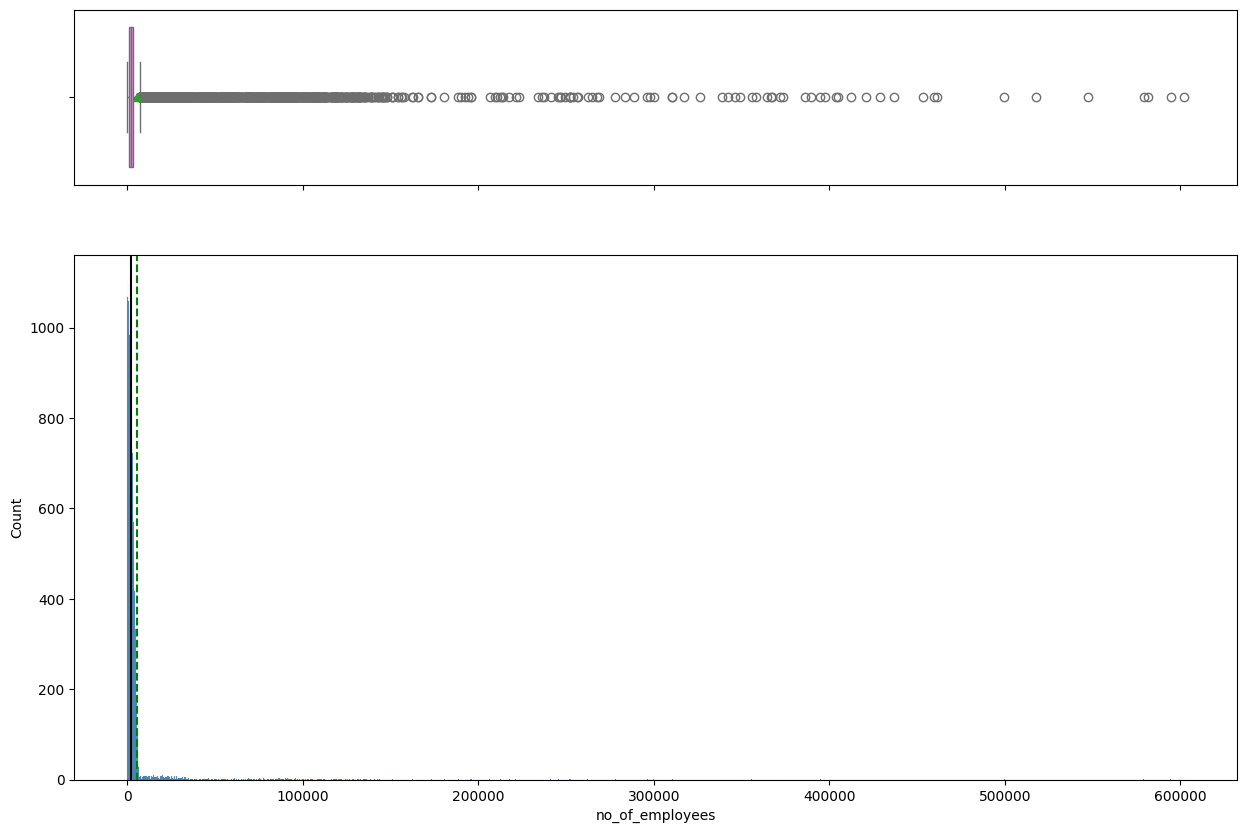

In [247]:
histogram_boxplot(data, 'no_of_employees')

In [248]:
data['no_of_employees'].nlargest()

21339    602069
1345     594472
20345    581468
11317    579004
9587     547172
Name: no_of_employees, dtype: int64

- The number of employees is skewed heavily to the right with most employers having under 4000 Employees.
- There are many outliers however we can assume these values to be true due to the existence of large employers within the US.
- The range is large with the minimum number of employees being 11 and the maximum being 602,069.


#### Observations on Prevailing Wage

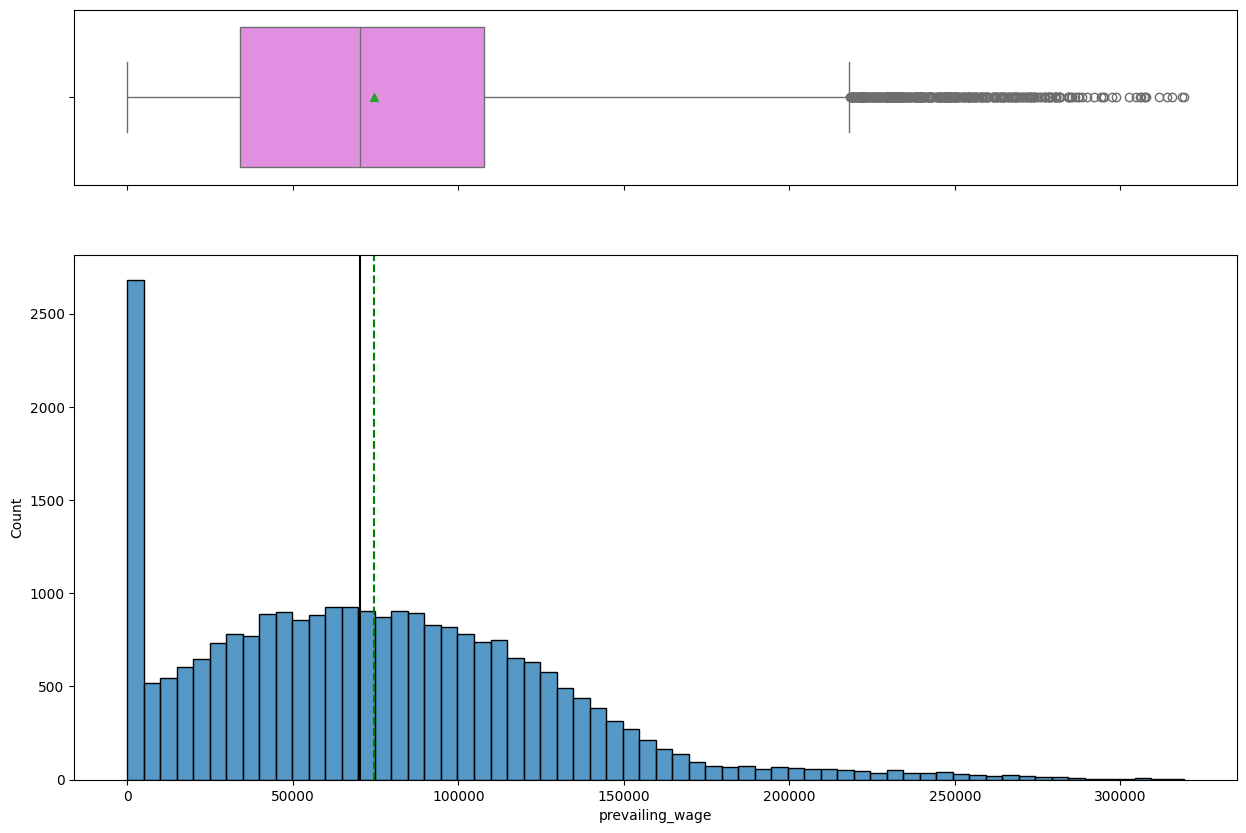

In [249]:
histogram_boxplot(data, 'prevailing_wage')

- The prevailing wage is left skewed with a large number of observations occuring at a the lower tail.
  - We noticed this earlier when looking at the statistical summary, but lets check to see that our assumption is correct that the low end of prevailing age is representing hourly wages.
- There are outliers at the higher end occuring over $225000, however we can assume these to be true values because these wages are within reason.


In [250]:
#check the unit of wage for prevailing wages below a 100
data.loc[data['prevailing_wage']< 100, 'unit_of_wage'].value_counts()

Hour    176
Name: unit_of_wage, dtype: int64

- Our assumption of low value wages being hourly is correct with all 176 being hourly wages.

#### Observations on Year Established

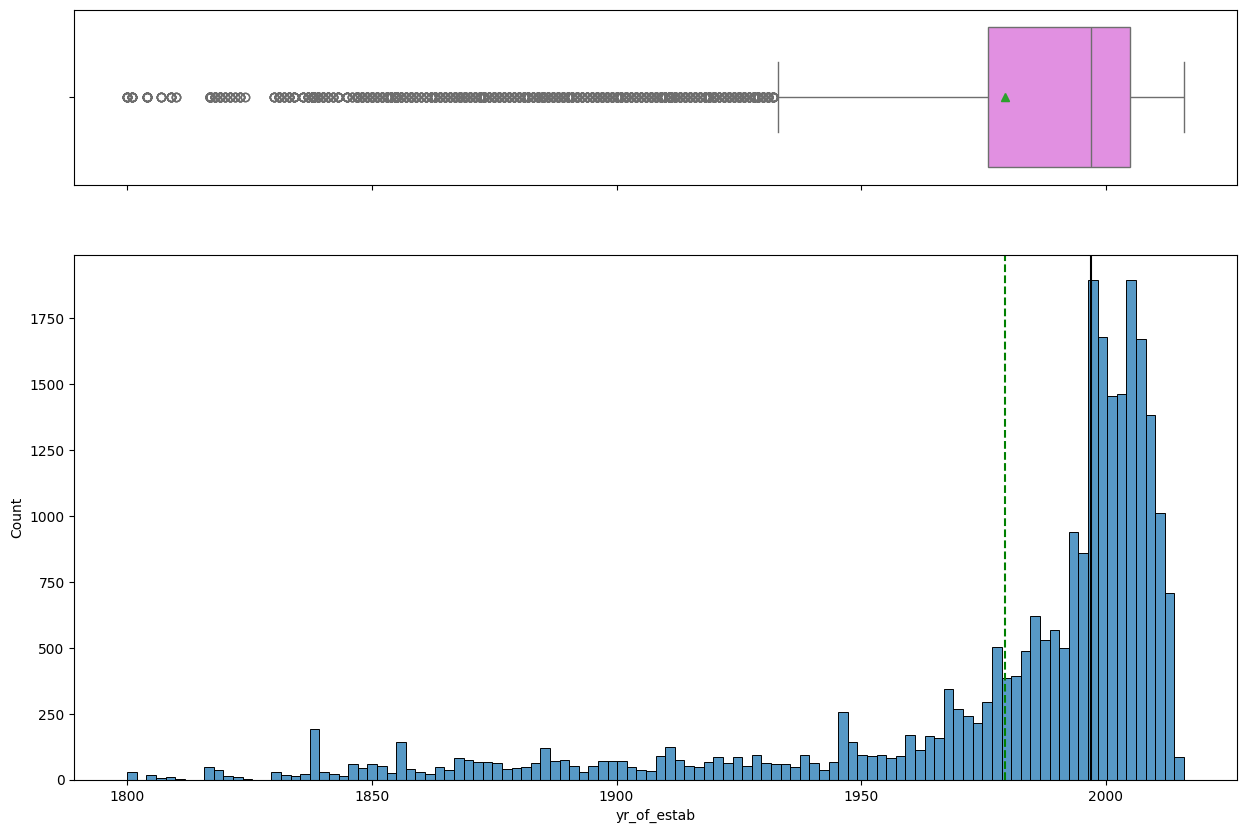

In [251]:
histogram_boxplot(data, 'yr_of_estab')

- The year established is left skewed with many outliers below the lower whisker.
- The average established year among companies in the data set is 1979 with the median being 1997.
- The oldest company was established in the 1800's.

#### Observations on Continent

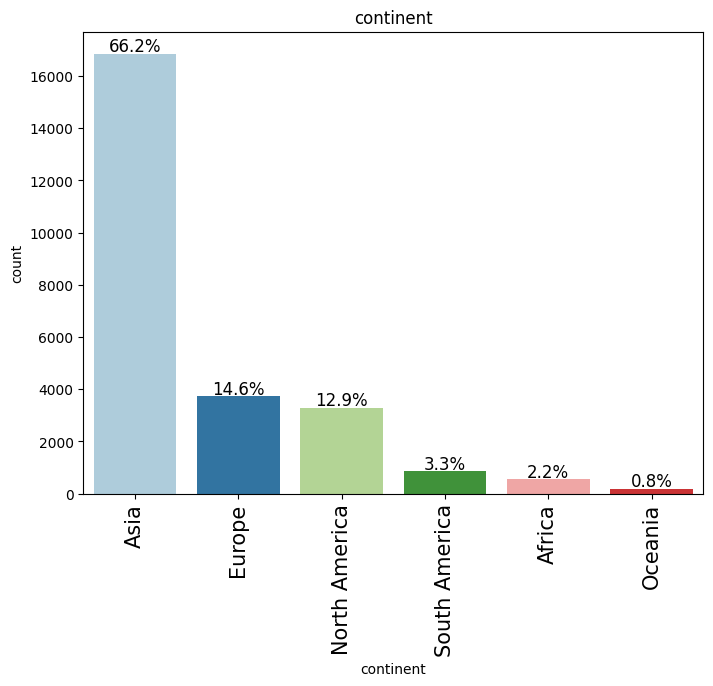

In [252]:
labeled_barplot(data, 'continent', perc=True)

- Asia represents  nearly 2/3 of the visa applications with 66.2% followed by Europe at 14.6% and North America at 12.9%.
- Oceania (0.8%) represents the least with less than 1% of the applications.

#### Observations on Employee Education

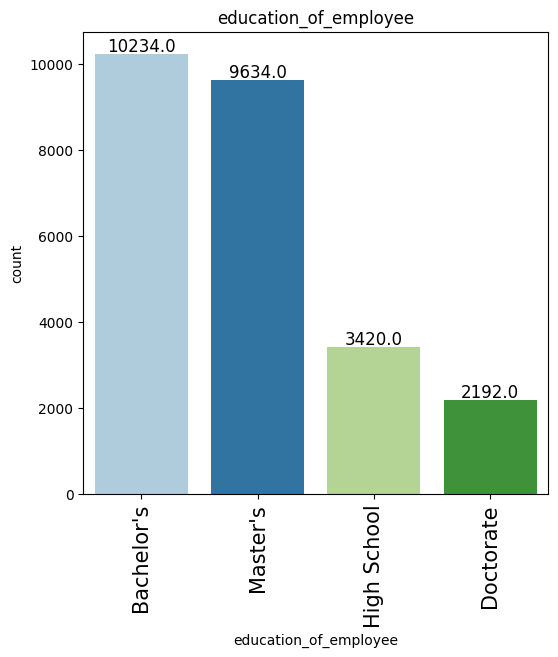

In [253]:
labeled_barplot(data, 'education_of_employee')

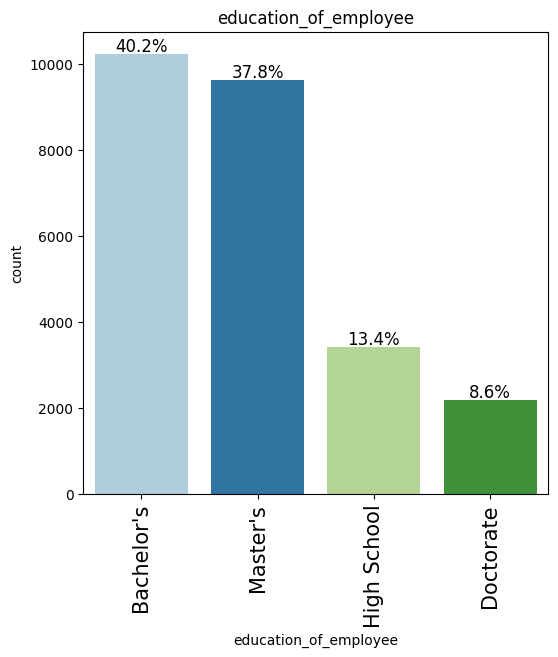

In [254]:
labeled_barplot(data, 'education_of_employee', perc=True)

- Bachelor's degrees are the most common with 10234 (40.2%), followed by Masters with 9634 (37.8%), High School with 3420 (13.4%), and Doctorate being the least common with 2192 (8.6%).

#### Observations on Job Experience

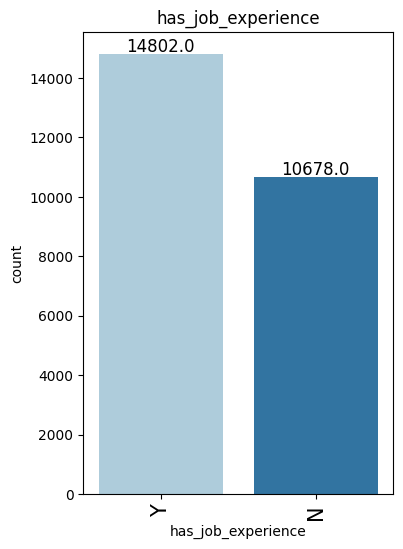

In [255]:
labeled_barplot(data, 'has_job_experience')

- 14802 have job experience while 10678 do not have job experience.

#### Observations on Job Training

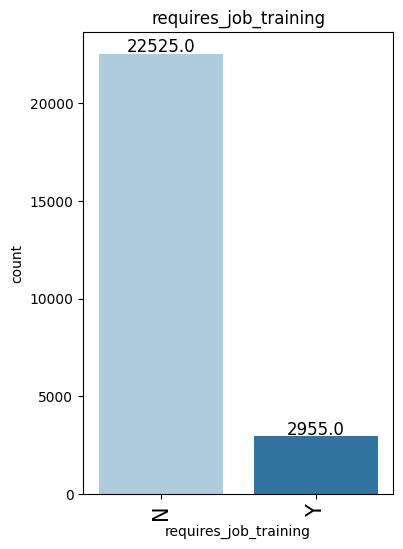

In [256]:
labeled_barplot(data, 'requires_job_training' )

- Most of the visa applications do not require job training with 22525 not requiring training and only 2955 requiring training.

#### Observations on Region of Employment

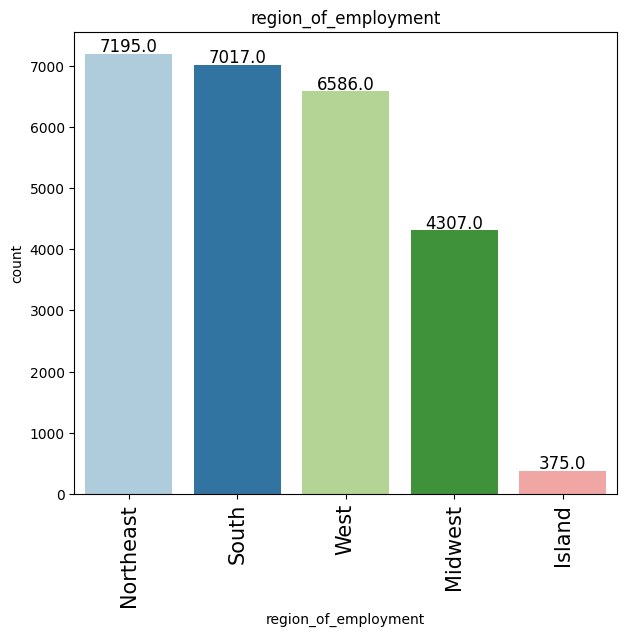

In [257]:
labeled_barplot(data, 'region_of_employment')

- Northeast, South and West are the most common with 7195, 7017, and 6568 respectively.
- The Midwest follows with 4307.
- Island has the least with only 375.

This makes sense due to population density and job market opportunities in each region

#### Observations on Unit of Wage

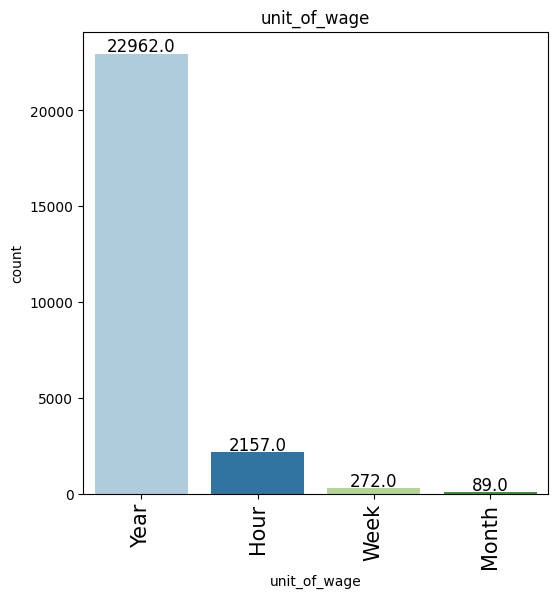

In [258]:
labeled_barplot(data, 'unit_of_wage')

- Yearly wage types are the most common with 22962 falling into this category.
- Monthly wages are the least common with only 89.
- Weekly wages are slightly more common than monthly with 272.
- Hourly is the closest to yearly with 2157.

#### Observations on Full Time Position

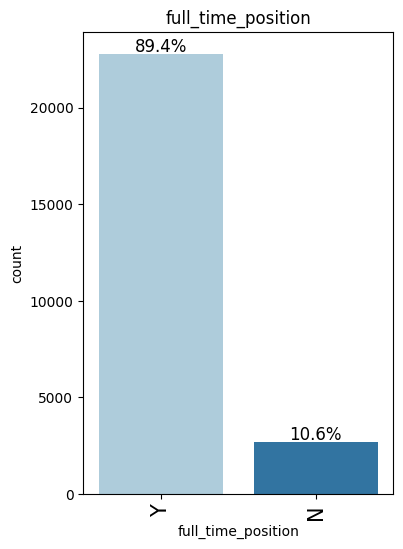

In [259]:
labeled_barplot(data, 'full_time_position', perc=True )

- 89.4% of visa applications are for full-time positions while 10.6% are part-time.

#### Observations on Case Status (Target/Dependent Variable)

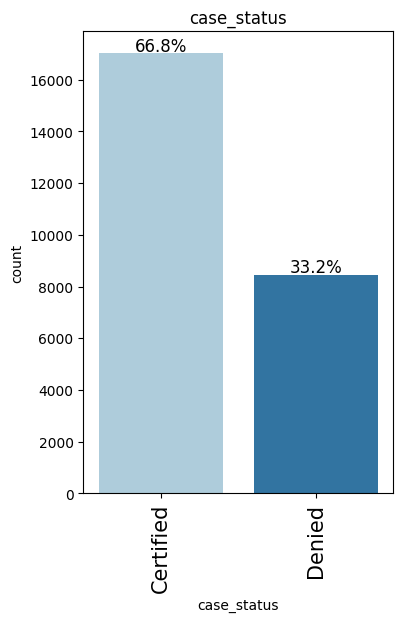

In [260]:
labeled_barplot(data, 'case_status' , perc=True)

- Of all visa applications in the data set 66.8% are certified and 33.2% are denied.

###Bivariate Analysis

In [261]:
#create a variable to list the numerical columns in the data set
cols_list= data.select_dtypes(include=np.number).columns.tolist()

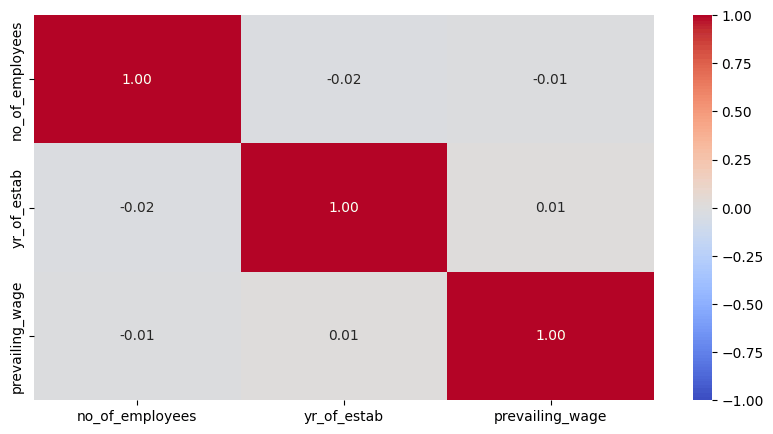

In [262]:
#visualize a heat map of the numerical columns
plt.figure(figsize= (10,5))
sns.heatmap(data[cols_list].corr(), annot= True, vmin=-1, vmax=1, fmt='.2f', cmap='coolwarm')
plt.show()

- There are no strong correlations among numerical variables in the dataset.

####Observations on Employee Education vs Case Status

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


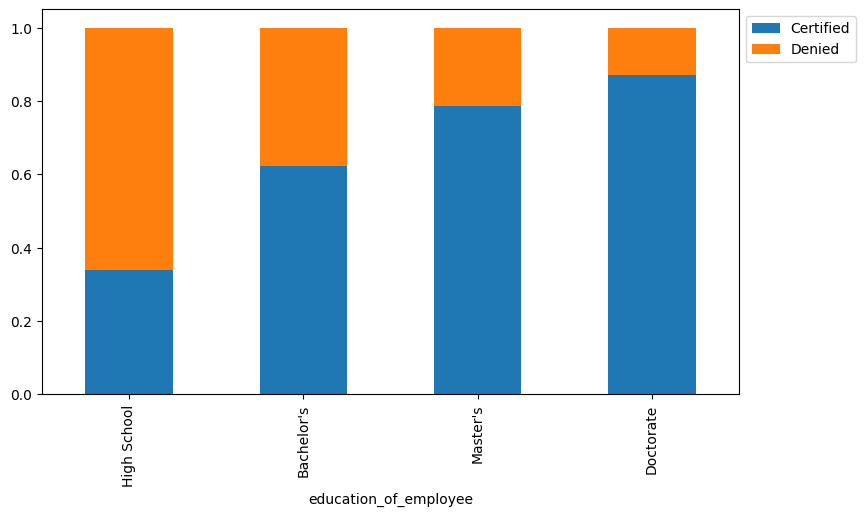

In [263]:
stacked_barplot(data, 'education_of_employee', 'case_status')

- As education increases from high school level to doctorate the rate of visa certification increases.
  - Highschool certification rate is ~35%
  - Doctorate certification rate is ~90%
- Education does seem to play a role in visa certification.

####Observations on Education vs Region

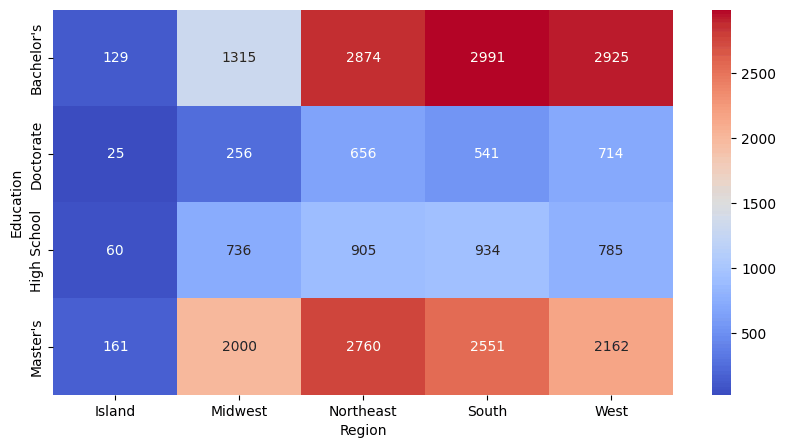

In [264]:
#visualize value counts for Education based on Region
plt.figure(figsize=(10,5))
sns.heatmap(pd.crosstab(data['education_of_employee'], data['region_of_employment']), annot=True, fmt='g', cmap='coolwarm')
plt.xlabel('Region')
plt.ylabel('Education')
plt.show()


region_of_employment   Island  Midwest  Northeast  South  West    All
education_of_employee                                                
All                       375     4307       7195   7017  6586  25480
Master's                  161     2000       2760   2551  2162   9634
Bachelor's                129     1315       2874   2991  2925  10234
High School                60      736        905    934   785   3420
Doctorate                  25      256        656    541   714   2192
------------------------------------------------------------------------------------------------------------------------


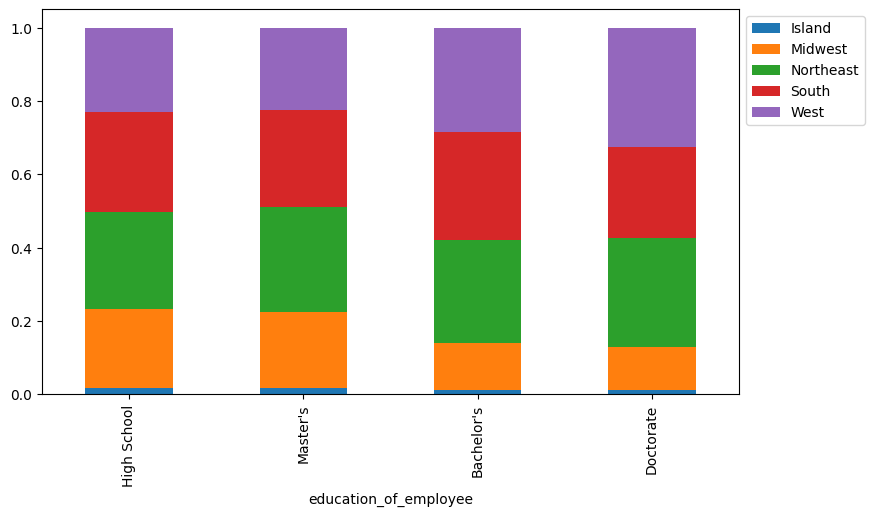

In [265]:
stacked_barplot(data, 'education_of_employee', 'region_of_employment')

- The West region contains largest instance of visa applications with a doctorate compared to other regions with 714 out of 2192, with the Northeast following at 656.  
- Bachelors Degrees which is the most common education levelis relatively similar across the Northeast (2874), South (2991) and West (2925). With South having the most.
- The overall proportions of education level represented between regions is relatively similar with some variance mostly seen in the Midwest, South, and West.

####Observations on Region vs Case Status

case_status           Certified  Denied    All
region_of_employment                          
All                       17018    8462  25480
Northeast                  4526    2669   7195
West                       4100    2486   6586
South                      4913    2104   7017
Midwest                    3253    1054   4307
Island                      226     149    375
------------------------------------------------------------------------------------------------------------------------


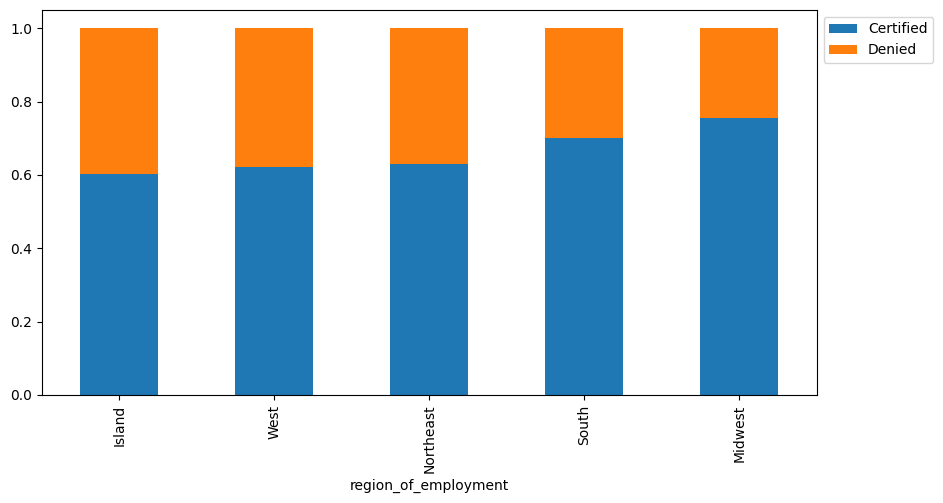

In [266]:
stacked_barplot(data, 'region_of_employment', 'case_status' )

- The Midwest region has the highest certified rate for visas followed by the South region
- The Island region has the lowest certified visa rate, followed by the West and Northeast Regions


####Observations on Continent vs Case Status

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


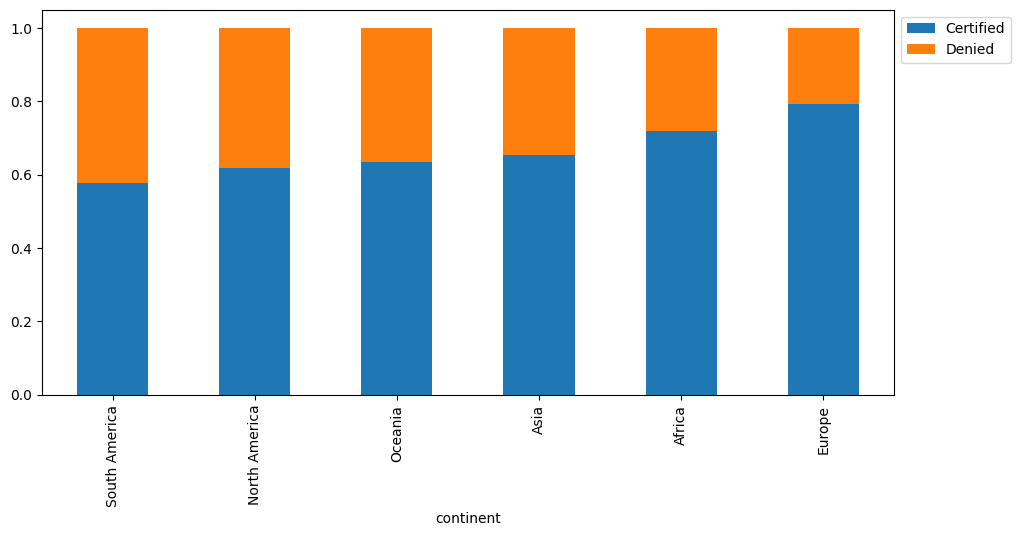

In [267]:
stacked_barplot(data, 'continent', 'case_status' )

- The lowest certified visa application rates are in South America, North America and Oceania, with South America having the most denied visa applications.
- The highest certified visa application rates are in Europe, Africa and Asia, with Europe having the least denied visa applications.

####Observations on Previous Work Experience vs Case Status

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


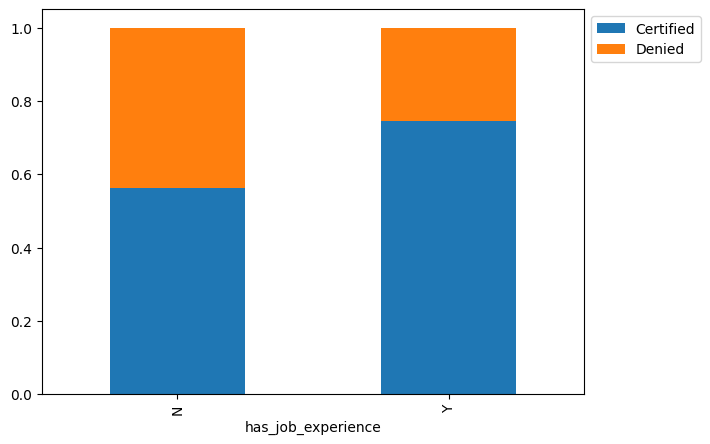

In [268]:
stacked_barplot(data, 'has_job_experience', 'case_status' )

- Previous job experience has a higher rate of Visa certification in comparison to no previous job experience.
  - Certified rate for having previous work experience ~76%
  - Certified rate for not having previous work experience ~57%
- This appears to show a relationship between previous work experience and whether a visa applications will be certified or denied.

####Observations on Job Training vs Case Status

case_status            Certified  Denied    All
requires_job_training                          
All                        17018    8462  25480
N                          15012    7513  22525
Y                           2006     949   2955
------------------------------------------------------------------------------------------------------------------------


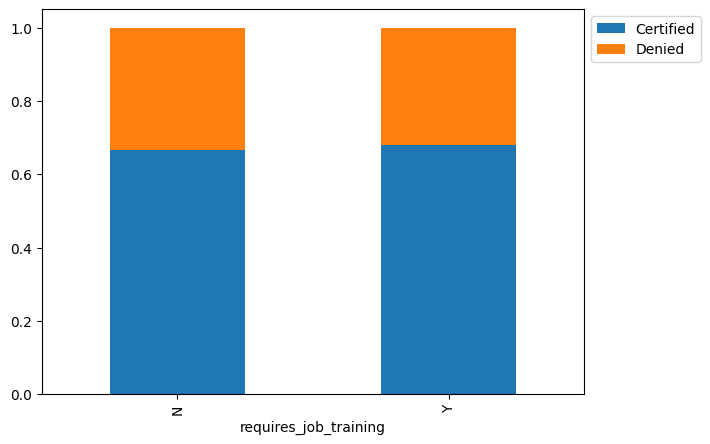

In [269]:
stacked_barplot(data, 'requires_job_training', 'case_status' )


-  Job training required seems to have little correlation to visa certification.
- The rates for certified Visas between requiring and not requiring job training are very similar in respect to visa certification.  

####Observations on Wage Type vs Case Status

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


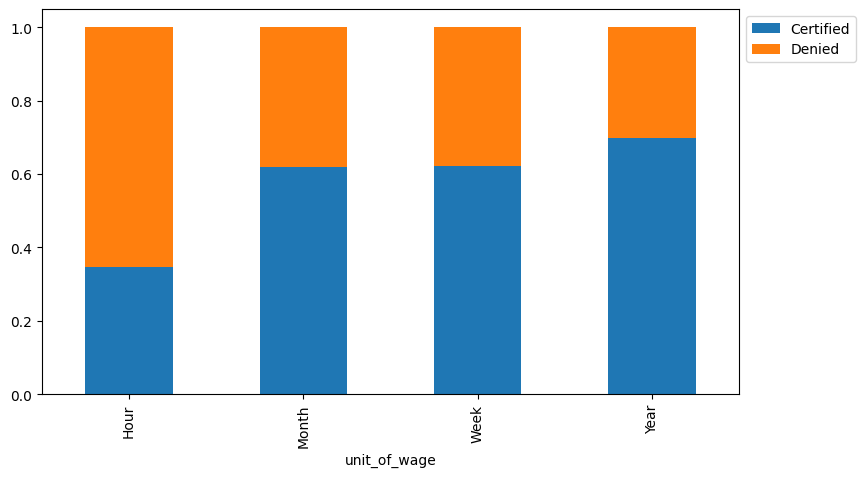

In [270]:
stacked_barplot(data, 'unit_of_wage', 'case_status' )

- Hourly pay is the least likely wage type on a visa application to be certified ~35%.
- Yearly pay is the most likely wage type on a visa application to be certified ~70%.


####Observations on Prevailing Wage with Respect to Case Status

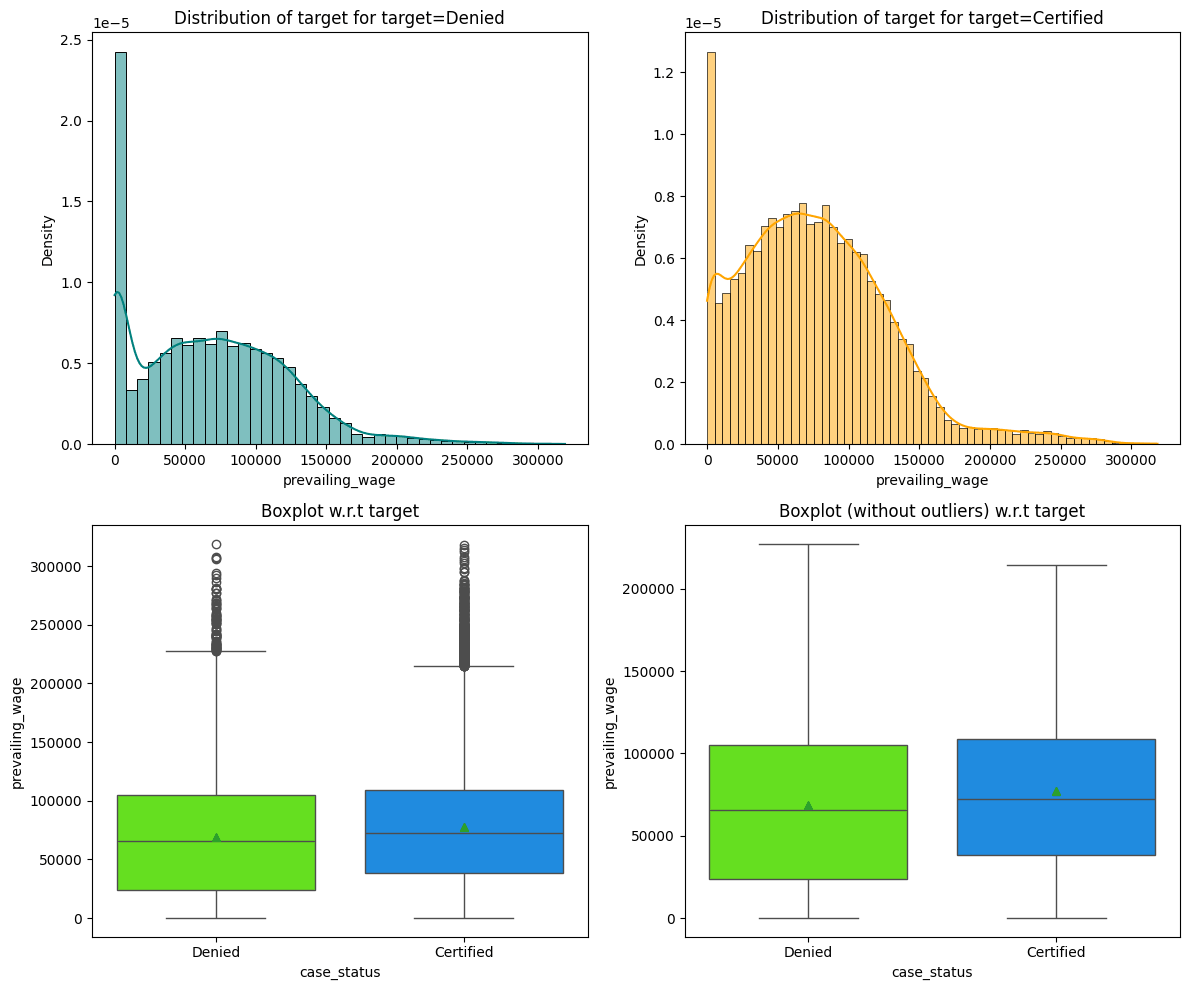

In [271]:
distribution_plot_wrt_target(data, 'prevailing_wage', 'case_status')

- The median and average prevailing wages for certified visa applications is slightly higher than denied applications.
- Visa Status tends to be relatively similar among prevailing wages.
- However if we combine this with the high rate of denied visa applications we can see there is a relationship between a lower prevailing wage and an increased likelihood of the application being denied.


####Observations on Prevailing Wage vs Region

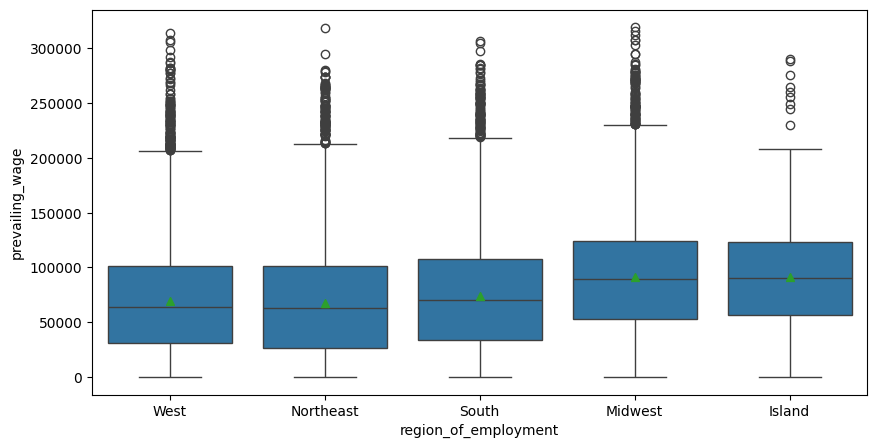

In [272]:
plt.figure(figsize=(10,5))
sns.boxplot(data, x='region_of_employment', y='prevailing_wage', showmeans= True)
plt.show()

- Prevailing wage on average is the highest in Island and Midwest regions.
- Midwest has the largest overall range among regions.
- The average and media prevailing wage is generally between 50,000 and 100,000 across all regions.
- The upper quartile across regions generally begins around 100,000 with Midwest and Island being 120,000.

## Data Preprocessing
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

###Outlier Check

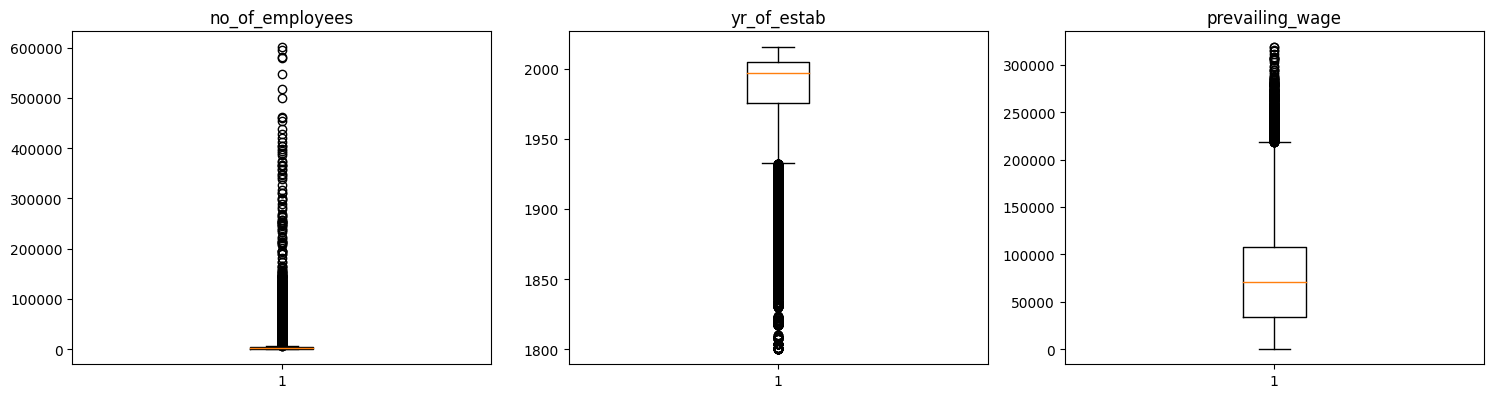

In [273]:
#visualize numeric columns for outlier check
plt.figure(figsize=(20, 15))

for i, variable in enumerate(cols_list):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- While there are many outliers present in each numeric variable, we have explored these and can safely assume the values are true values.

###Data Preparation for Modeling

- Our target is to predict which Visa will be certified
- We will first encode the target variable
- Then we will split the data into train and test sets

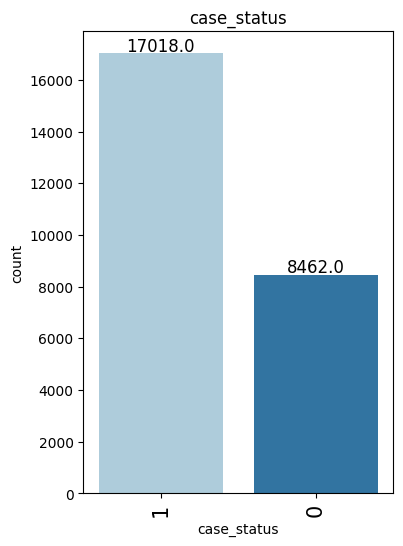

In [274]:
#change case status to numerical classifier
data['case_status']= data['case_status'].apply(
    lambda x:
    1 if x == 'Certified'
    else 0
    )

labeled_barplot(data, 'case_status')

Conversion to numerical classifier completed
1 = Certified
0 = Denied

In [275]:
#Split data into independent and dependent variables
X= data.drop(['case_status'], axis=1)
y= data['case_status']

#creating the dummie variables
X= pd.get_dummies(X, drop_first=True)

#splitting data into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.30, random_state=1, stratify = y
)
print(X.head())
print( "\n")
print('dependent variable\n', y.head())

   no_of_employees  yr_of_estab  prevailing_wage  continent_Asia  \
0            14513         2007         592.2029               1   
1             2412         2002       83425.6500               1   
2            44444         2008      122996.8600               1   
3               98         1897       83434.0300               1   
4             1082         2005      149907.3900               0   

   continent_Europe  continent_North America  continent_Oceania  \
0                 0                        0                  0   
1                 0                        0                  0   
2                 0                        0                  0   
3                 0                        0                  0   
4                 0                        0                  0   

   continent_South America  education_of_employee_Doctorate  \
0                        0                                0   
1                        0                                0   

In [276]:
X.shape

(25480, 21)

- We now have 21 columns in the independent variable data

In [277]:
#check the first 5 rows of X to view dummies split
X.head()

,no_of_employees,yr_of_estab,prevailing_wage,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America,education_of_employee_Doctorate,education_of_employee_High School,education_of_employee_Master's,has_job_experience_Y,requires_job_training_Y,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year,full_time_position_Y
0,14513,2007,592.2029,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1
1,2412,2002,83425.6500,1,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1
2,44444,2008,122996.8600,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1
3,98,1897,83434.0300,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1
4,1082,2005,149907.3900,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,1


In [278]:
#check to see that the split worked correctly
print('X_train shape', X_train.shape)
print('X_test shape', X_test.shape)
print('y_train shape', y_train.shape )
print('y_test shape', y_test.shape)
print('Percentage of classes in test set:')
print(y_train.value_counts(normalize=True))
print('Percentage of classes in test set:')
print(y_test.value_counts(normalize=True))

X_train shape (17836, 21)
X_test shape (7644, 21)
y_train shape (17836,)
y_test shape (7644,)
Percentage of classes in test set:
1    0.667919
0    0.332081
Name: case_status, dtype: float64
Percentage of classes in test set:
1    0.667844
0    0.332156
Name: case_status, dtype: float64


- We see that the proportion of certified (1) 66.7% and Denied (0) 33.2% is preserved in both training and test sets.
- We have 17,836 observations in the training set and 7,644 observations in the test set

##Model Evaluation Criterion

In context of the problem statement we are looking to predict the certification of a visa application.

- We will fit different types of models on the train and data set and measure their performance.
- We will then try to imporve the performance by tuning with hyperparameters specific to each algorithm.
  - We will use GridSearchCV for hyperparameter tuning and decide on a target metric to optimize the model.



### Prediction Errors

There are two types of errors we can encounter:

1. False Positive (FP) - Predicting the visa application be certified but in actuality the visa application will be denied.
2. False Negative (FN) - Predicting the visa application be denied but in actuality the visa application will be certified.

###Which case is more Important?

Both cases can be considered important

- (FP) If a visa were to be certified when it should have been denied, the employee will be given an underserved opportunity at the expense of another visa applicant deserving of the opportunity or a U.S. citizen deserving of the opportunity.
- (FN) If a visa were to be denied when it should have been certified, the opportunity loss of having a qualified individual suitable for the opportunity would be missed.


###Which Metric should we optimize

- The F1 Score should be maximized for visa application status, since F1 considers 2 performance metrics; precision and recall reducing the instance of both false positives and false negatives.
- Due to this we will use balanced class weight so the models focusses on both classes equally.


##Define Functions for model evaluation

- The model_performance_classification_sklearn function will be used to check the model performance of models.
- The confusion_matrix_sklearn function will be used to plot the confusion matrix.

In [279]:
#defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification_sklearn(model, predictors, target):
  """
  Function to compute metrics to check classification model performance

  model: classifier
  predictors: independent variables
  target: dependent variables

  """

  #predicting using the independent variables
  pred= model.predict(predictors)

  acc = accuracy_score(target, pred) #compute Accuracy
  recall = recall_score(target, pred) #compute Recall
  precision = precision_score(target, pred) #compute Precision
  f1 = f1_score(target, pred) #compute F1-Score

    #creating a dataframe for the metrics
  df_perf = pd.DataFrame(
      {'Accuracy': acc, 'Recall': recall, 'Precision': precision, 'F1':f1},index=[0]

  )

  return df_perf

In [280]:
def confusion_matrix_sklearn(model, predictors, target):
  """
  To plot the confusion_matrix with percentages
  model: classifier
  predictors: independent variables
  target: dependent variable

  """
  y_pred = model.predict(predictors)
  cm = confusion_matrix(target, y_pred)
  labels = np.asarray(
      [
          ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
          for item in cm.flatten()
          ]
      ).reshape(2, 2)

  plt.figure(figsize=(6, 4))
  sns.heatmap(cm, annot=labels, fmt="")
  plt.ylabel("True label")
  plt.xlabel("Predicted label")

##Decision Tree - Model Building and Hyperparameter Tuning

###Model Building

In [281]:
#create initial tree
model = DecisionTreeClassifier(random_state=1)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=1)

####Checking the model performance on training set

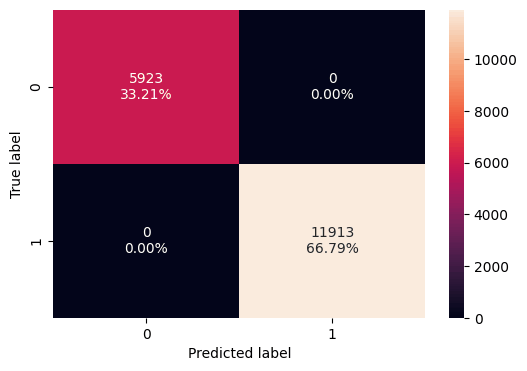

In [282]:
confusion_matrix_sklearn(model, X_train, y_train)

In [283]:
decision_tree_perf_train= model_performance_classification_sklearn(model, X_train, y_train)
print('Training Performance \n' ,decision_tree_perf_train)

Training Performance 
    Accuracy  Recall  Precision   F1
0       1.0     1.0        1.0  1.0


####Checking the model performance on test set

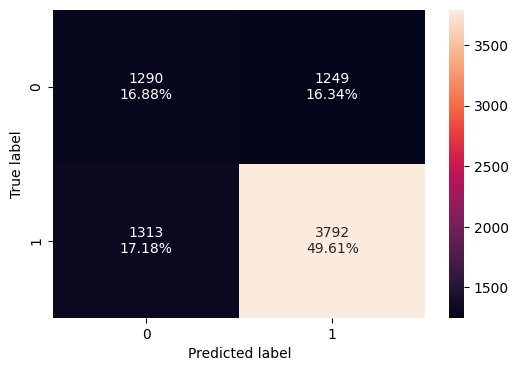

In [284]:
confusion_matrix_sklearn(model, X_test, y_test)

In [285]:
decision_tree_perf_test= model_performance_classification_sklearn(model, X_test, y_test)
print('Test Performance \n' ,decision_tree_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.664835  0.742801   0.752232  0.747487


- The Decision Tree Classifier Model with default parameters is performing perfectly on the training set, but its performance on the test set shows overfitting when compared to the training performance.
- We will attempt to reduce the overfitting and improve performance on test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.75

###Hyperparameter Tuning - Decision Tree

Using GridSearch for Hyperparameter tuning model
- Hyperparameter tuning is also tricky in the sense that there is no direct way to calculate how a change in the hyperparameter value will reduce the loss of your model, so we usually resort to experimentation. i.e we'll use Grid search
- Grid search is a tuning technique that attempts to compute the optimum values of hyperparameters.
- It is an exhaustive search that is performed on a the specific parameter values of a model.
- The parameters of the estimator/model used to apply these methods are optimized by cross-validated grid-search over a parameter grid.

In [286]:
#choose the type of classifier
dtree_classifier = DecisionTreeClassifier(class_weight='balanced', random_state=1)

# Grid of parameters to choose from
parameters = {
    "max_depth": np.arange(10, 20, 5),
    "min_samples_leaf": [3, 5],
    "max_leaf_nodes": [2, 3, 5],
    "min_impurity_decrease": [0.0001, 0.001],
}

#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(dtree_classifier, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
dtree_classifier= grid_obj.best_estimator_

#fit the best algorithm to the data
dtree_classifier.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=10, max_leaf_nodes=2,
                       min_impurity_decrease=0.0001, min_samples_leaf=3,
                       random_state=1)

####Checking the model performance on training set

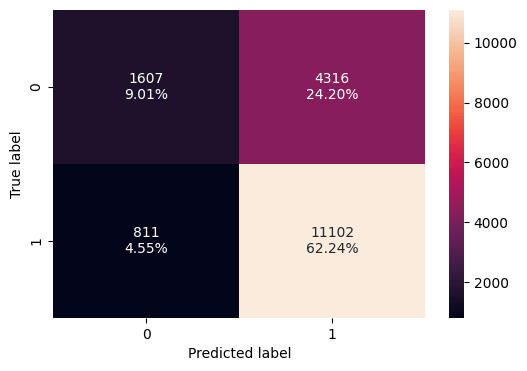

In [287]:
confusion_matrix_sklearn(dtree_classifier, X_train, y_train)

In [288]:
dtree_classifier_model_perf_train= model_performance_classification_sklearn(dtree_classifier, X_train, y_train)
print('Train Performance \n' ,dtree_classifier_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.712548  0.931923   0.720067  0.812411


####Checking the model performance on test set

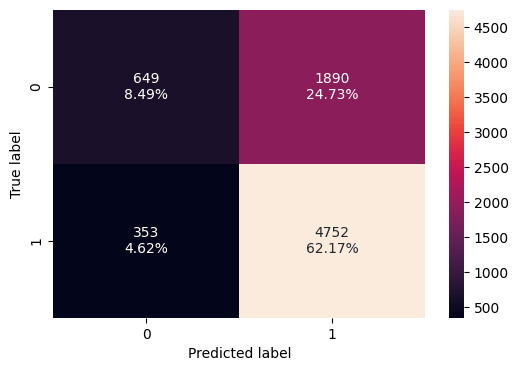

In [289]:
confusion_matrix_sklearn(dtree_classifier, X_test, y_test)

In [290]:
dtree_classifier_model_perf_test= model_performance_classification_sklearn(dtree_classifier, X_test, y_test)
print('Test Performance \n' ,dtree_classifier_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.706567  0.930852   0.715447  0.809058


- The overfitting is reduced after hyperparameter tuning, with comparable performance between the train and test sets.
  - The model is showing improved generalization  and is no longer overfitting.
- The F1 Metric has also improved from default parameters 0.75 to hyperparameter tuned 0.81 increasing by ~.06

##Bagging - Model Building and Hyperparameter Tuning

###Model Building

In [291]:
bagging = BaggingClassifier(random_state=1)
bagging.fit(X_train, y_train)

BaggingClassifier(random_state=1)

####Checking the model performance on training set

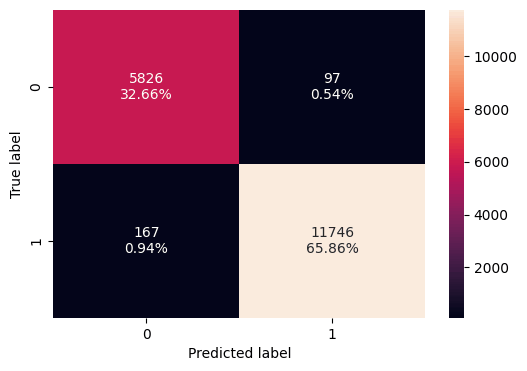

In [292]:
confusion_matrix_sklearn(bagging, X_train, y_train)

In [293]:
bagging_model_perf_train = model_performance_classification_sklearn(bagging, X_train, y_train)
print('Train Performance \n' ,bagging_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.985198  0.985982    0.99181  0.988887


####Checking the model performance on test set

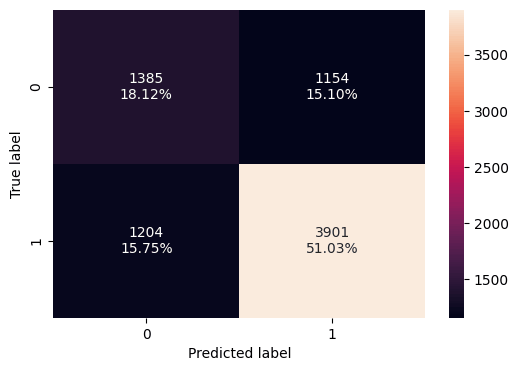

In [294]:
confusion_matrix_sklearn(bagging, X_test, y_test)

In [295]:
bagging_model_perf_test = model_performance_classification_sklearn(bagging, X_test, y_test)
print('Test performance \n' ,bagging_model_perf_test)

Test performance 
    Accuracy    Recall  Precision        F1
0  0.691523  0.764153   0.771711  0.767913


- The Bagging Classifier Model with default parameters is performing very well on the training set, but its performance on the test set shows overfitting when compared to the training performance.
- We will attempt to reduce the overfitting and improve performance on the test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.77

###Hyperparameter Tuning  - Bagging

In [296]:
#choose the type of classifier
bagging_classifier_tuned = BaggingClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {
    "max_samples": [0.7, 0.8],
    "max_features": [0.5,0.7,1],
    "n_estimators": np.arange(50,110,25),
}

#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(bagging_classifier_tuned, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
bagging_classifier_tuned= grid_obj.best_estimator_

#fit the best algorithm to the data
bagging_classifier_tuned.fit(X_train, y_train)

BaggingClassifier(max_features=0.7, max_samples=0.7, n_estimators=100,
                  random_state=1)

####Checking the model performance on training set

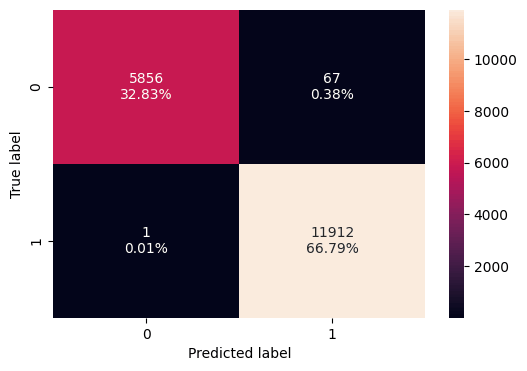

In [297]:
confusion_matrix_sklearn(bagging_classifier_tuned, X_train, y_train)

In [298]:
bagging_classifier_tuned_model_perf_train = model_performance_classification_sklearn(bagging_classifier_tuned, X_train, y_train)
print('Train Performance \n' ,bagging_classifier_tuned_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.996187  0.999916   0.994407  0.997154


####Checking the model performance on test set

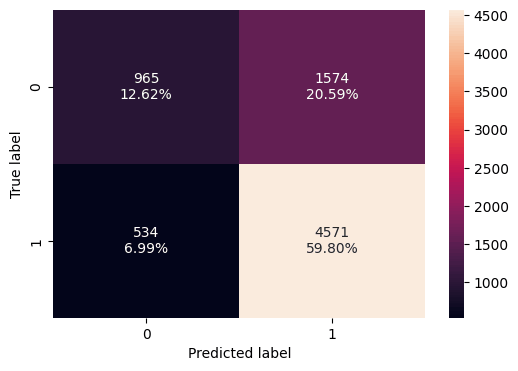

In [299]:
confusion_matrix_sklearn(bagging_classifier_tuned, X_test, y_test)

In [300]:
bagging_classifier_tuned_model_perf_test = model_performance_classification_sklearn(bagging_classifier_tuned, X_test, y_test)
print('Test Performance \n' ,bagging_classifier_tuned_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.724228  0.895397   0.743857  0.812622


- The overfitting is reduced after hyperparameter tuning, with comparable performance between the train and test performance.
  - The model is showing improved generalization  and is no longer overfitting.
- The F1 Metric has also improved from default parameters 0.77 to hyperparameter tuned 0.81 increasing by ~.04

##Random Forest - Model Building and Hyperparameter Tuning

###Model Building

In [301]:
rf = RandomForestClassifier(random_state=1)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=1)

####Checking the model performance on training set

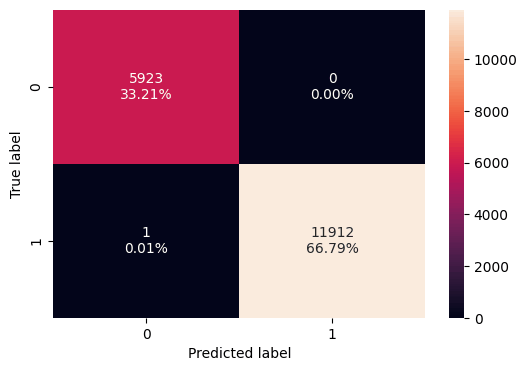

In [302]:
confusion_matrix_sklearn(rf, X_train, y_train)

In [303]:
rf_model_perf_train = model_performance_classification_sklearn(rf, X_train, y_train)
print('Train Performance \n' ,rf_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.999944  0.999916        1.0  0.999958


####Checking the model performance on test set

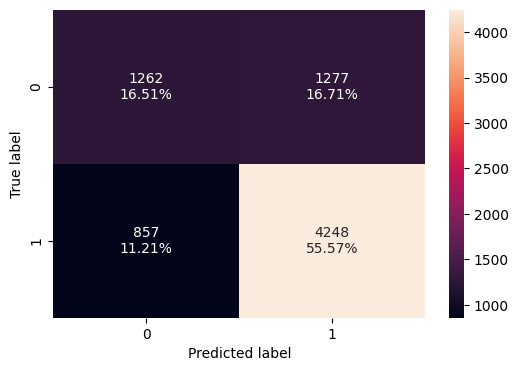

In [304]:
confusion_matrix_sklearn(rf, X_test, y_test)

In [305]:
rf_model_perf_test = model_performance_classification_sklearn(rf, X_test, y_test)
print('Test Performance \n' ,rf_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.720827  0.832125   0.768869  0.799247


- The Random Forest Classifier Model with default parameters is performing very well on the training set, but its performance on the test set shows overfitting when compared to the training performance.
- We will attempt to reduce the overfitting and improve performance on test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.80

###Hyperparameter Tuning  - Random Forest

In [306]:
# Choose the type of classifier.
rf_tuned = RandomForestClassifier(random_state=1, oob_score= True, bootstrap= True)

# Grid of parameters to choose from
parameters = {
    "max_depth": list(np.arange(5, 15, 5)),
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [3, 5, 7],
    "n_estimators": np.arange(10, 40, 10),
}

#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
rf_tuned= grid_obj.best_estimator_

#fit the best algorithm to the data
rf_tuned.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_split=7, n_estimators=20,
                       oob_score=True, random_state=1)

####Checking the model performance on training set

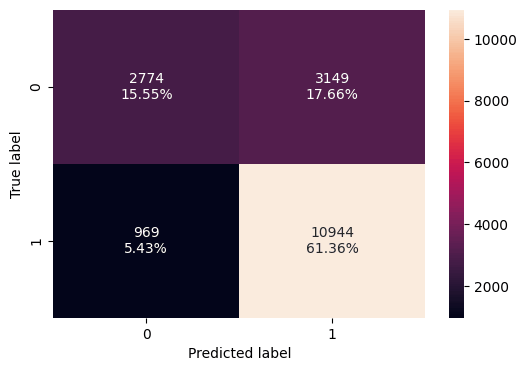

In [307]:
confusion_matrix_sklearn(rf_tuned, X_train, y_train)

In [308]:
rf_tuned_model_perf_train = model_performance_classification_sklearn(rf_tuned, X_train, y_train)
print('Train Performance \n' ,rf_tuned_model_perf_train)

Train Performance 
    Accuracy   Recall  Precision        F1
0  0.769119  0.91866   0.776556  0.841652


####Checking the model performance on test set

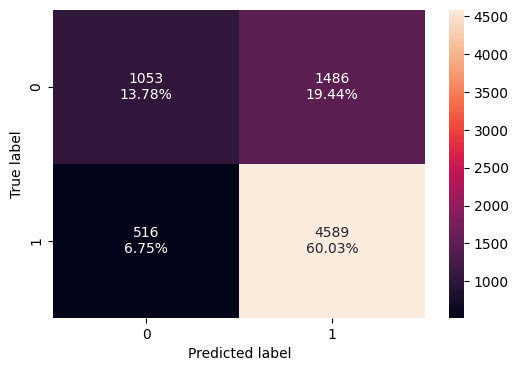

In [309]:
confusion_matrix_sklearn(rf_tuned, X_test, y_test)

In [310]:
rf_tuned_model_perf_test = model_performance_classification_sklearn(rf_tuned, X_test, y_test)
print('Test Performance \n' ,rf_tuned_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision       F1
0  0.738095  0.898923   0.755391  0.82093


- The overfitting is reduced after hyperparameter tuning, with comparable performance between the train and test performance.
  - The model is showing improved generalization  and is no longer overfitting.
- The F1 Metric has also improved from default parameters 0.80 to hyperparameter tuned 0.82 increasing by ~.02

##Boosting - Model Building and Hyperparameter Tuning


###Model Building - AdaBoost Classifier


In [311]:
ab_classifier = AdaBoostClassifier(random_state=1)
ab_classifier.fit(X_train, y_train)

AdaBoostClassifier(random_state=1)

####Checking the model performance on training set

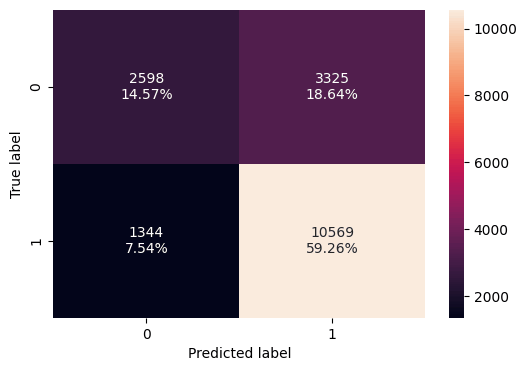

In [312]:
confusion_matrix_sklearn(ab_classifier, X_train, y_train)

In [313]:
ab_classifier_model_perf_train = model_performance_classification_sklearn(ab_classifier, X_train, y_train)
print('Train Performance \n' ,ab_classifier_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision       F1
0  0.738226  0.887182   0.760688  0.81908


####Checking the model performance on test set

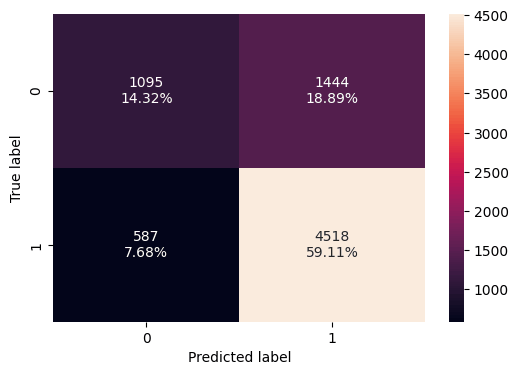

In [314]:
confusion_matrix_sklearn(ab_classifier, X_test, y_test)

In [315]:
ab_classifier_model_perf_test = model_performance_classification_sklearn(ab_classifier, X_test, y_test)
print('Test Performance \n' ,ab_classifier_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.734301  0.885015   0.757799  0.816481


- The AdaBoost Classifier Model with default parameters is performing well on the training set with comparable performance on the test set.
  - The model is showing good generalization  and is not overfitting.
- We will attempt improve performance on the test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.82

###Hyperparameter Tuning - AdaBoost Classifier

In [316]:
# Choose the type of classifier.
ab_tuned = AdaBoostClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {'n_estimators': np.arange(10,100,10),
              'learning_rate': [1, 0.1, 0.5, 0.01],
              }

#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(ab_tuned, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
ab_tuned= grid_obj.best_estimator_

#fit the best algorithm to the data
ab_tuned.fit(X_train, y_train)

AdaBoostClassifier(learning_rate=0.5, n_estimators=30, random_state=1)

####Checking the model performance on training set

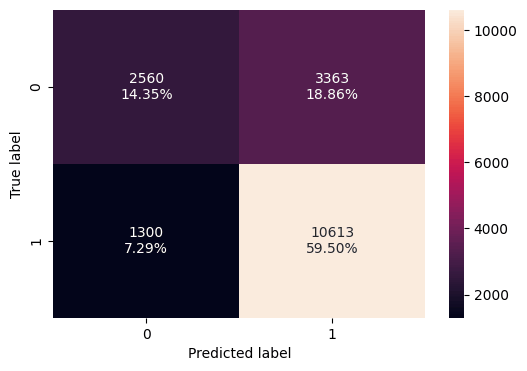

In [317]:
confusion_matrix_sklearn(ab_tuned, X_train, y_train)

In [318]:
ab_tuned_model_perf_train = model_performance_classification_sklearn(ab_tuned, X_train, y_train)
print('Train Performance \n' ,ab_tuned_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.738562  0.890876   0.759373  0.819885


####Checking the model performance on test set

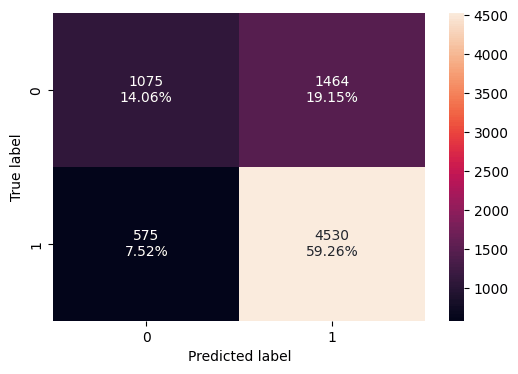

In [319]:
confusion_matrix_sklearn(ab_tuned, X_test, y_test)

In [320]:
ab_tuned_model_perf_test = model_performance_classification_sklearn(ab_tuned, X_test, y_test)
print('Test Performance \n' ,ab_tuned_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision       F1
0  0.733255  0.887365   0.755756  0.81629


- The tuned model is showing comparable metrics between training and test set performances showing good generalization.
- The default parameter model and the hyperparemeter tuned model are performing at the same level with the F1 score on the test set being 0.82 in both models.

###Model Building - Gradient Boost Classifier


In [321]:
gb_classifier = GradientBoostingClassifier(random_state=1)
gb_classifier.fit(X_train, y_train)

GradientBoostingClassifier(random_state=1)

####Checking the model performance on training set

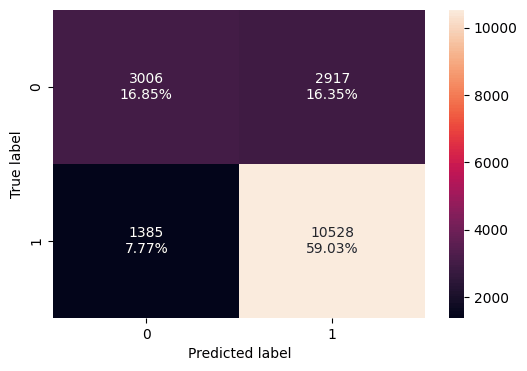

In [322]:
confusion_matrix_sklearn(gb_classifier, X_train, y_train)

In [323]:
gb_classifier_model_perf_train = model_performance_classification_sklearn(gb_classifier, X_train, y_train)
print('Train Performance \n' ,gb_classifier_model_perf_train)

Train Performance 
    Accuracy   Recall  Precision        F1
0  0.758802  0.88374   0.783042  0.830349


####Checking the model performance on test set

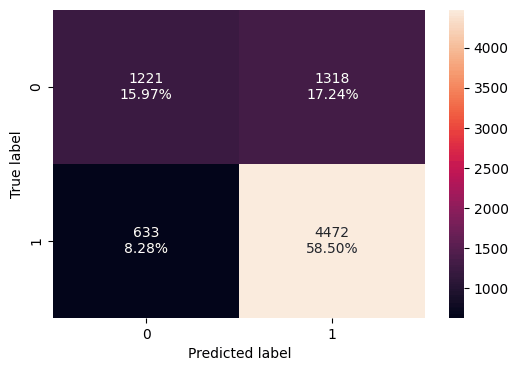

In [324]:
confusion_matrix_sklearn(gb_classifier, X_test, y_test)

In [325]:
gb_classifier_model_perf_test = model_performance_classification_sklearn(gb_classifier, X_test, y_test)
print('Test Performance \n' ,gb_classifier_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.744767  0.876004   0.772366  0.820927


- The Gradient Boost Classifier Model with default parameters is performing well on the training set with comparable performance on the test set.
  - The model is showing good generalization and is not overfitting.
- We will attempt improve performance on the test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.82

###Hyperparameter Tuning - Gradient Boost Classifier

In [326]:
# Choose the type of classifier.
gb_tuned = GradientBoostingClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {
    "n_estimators": np.arange(50,110,25),
    "subsample": [0.7,0.9],
    "max_features": [0.7, 0.8, 0.9, 1],
    "learning_rate": [0.01,0.1,0.05],
}


#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(gb_tuned, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
gb_tuned= grid_obj.best_estimator_

#fit the best algorithm to the data
gb_tuned.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, max_features=0.8, random_state=1,
                           subsample=0.9)

####Checking the model performance on training set

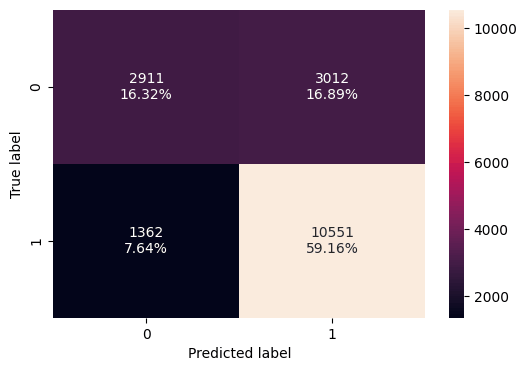

In [327]:
confusion_matrix_sklearn(gb_tuned, X_train, y_train)

In [328]:
gb_tuned_model_perf_train = model_performance_classification_sklearn(gb_tuned, X_train, y_train)
print('Train Performance \n' ,gb_tuned_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.754766  0.885671   0.777925  0.828309


####Checking the model performance on test set

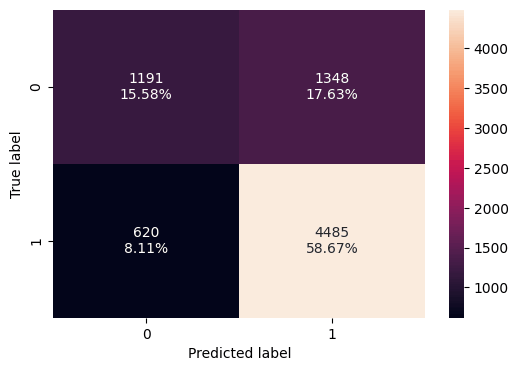

In [329]:
confusion_matrix_sklearn(gb_tuned, X_test, y_test)

In [330]:
gb_tuned_model_perf_test = model_performance_classification_sklearn(gb_tuned, X_test, y_test)
print('Test Performance \n' ,gb_tuned_model_perf_test)

Test Performance 
    Accuracy   Recall  Precision        F1
0  0.742543  0.87855   0.768901  0.820077


- The tuned model is showing comparable metrics between training and test set performances showing good generalization.
- The default parameter model and the hyperparemeter tuned model are performing at the same level with the F1 score on the test set being 0.82 in both models.

###Model Building - XGBoost Classifier


In [331]:
xgb_classifier = XGBClassifier(random_state=1, verbosity = 0)
xgb_classifier.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=1, ...)

####Checking the model performance on training set

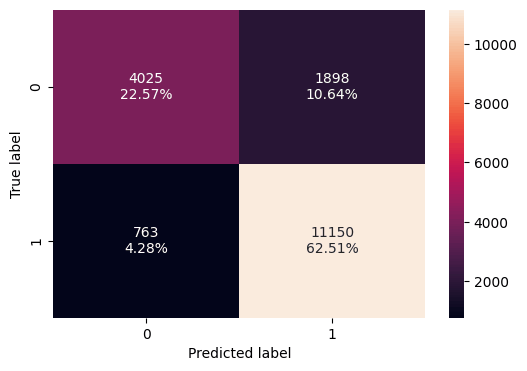

In [332]:
confusion_matrix_sklearn(xgb_classifier, X_train, y_train)

In [333]:
xgb_classifier_model_perf_train = model_performance_classification_sklearn(xgb_classifier, X_train, y_train)
print('Train Performance \n' ,xgb_classifier_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0  0.850807  0.935952   0.854537  0.893394


####Checking the model performance on test set

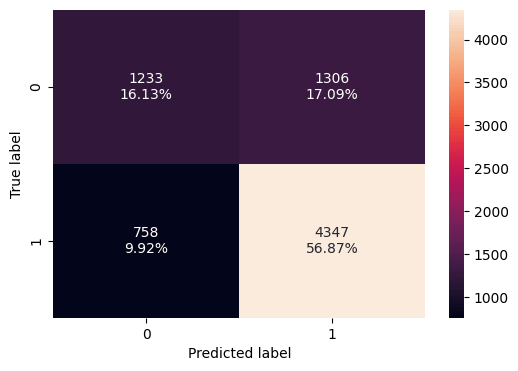

In [334]:
confusion_matrix_sklearn(xgb_classifier, X_test, y_test)

In [335]:
xgb_classifier_model_perf_test = model_performance_classification_sklearn(xgb_classifier, X_test, y_test)
print('Test Performance \n' ,xgb_classifier_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.729984  0.851518   0.768972  0.808143


- The XGBoost Classifier Model with default parameters is performing well on the training set, but its performance on the test set shows overfitting when compared to the training performance.
- We will attempt to reduce the overfitting and improve performance on test set by implementing hyperparemeter tuning.
- The F1 on the test set is 0.81

###Hyperparameter Tuning - Gradient Boost Classifier

In [336]:
# Choose the type of classifier.
xgb_tuned = XGBClassifier(random_state=1, eval_metric='logloss')

# Grid of parameters to choose from
parameters = {
    "n_estimators": np.arange(50,110,25),
    "scale_pos_weight": [1,2,5],
    "subsample": [0.9, 1],
    "learning_rate": [0.01,0.1,0.05],
    "gamma": [1,3]
}


#set the scoring type used to compare paremter combinations
f1_scorer= metrics.make_scorer(metrics.f1_score)

#run the grid search
grid_obj = GridSearchCV(xgb_tuned, parameters, scoring=f1_scorer, cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

#set the clf to the best combination of parameters
xgb_tuned= grid_obj.best_estimator_

#fit the best algorithm to the data
xgb_tuned.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=3, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=50,
              n_jobs=None, num_parallel_tree=None, random_state=1, ...)

####Checking the model performance on training set

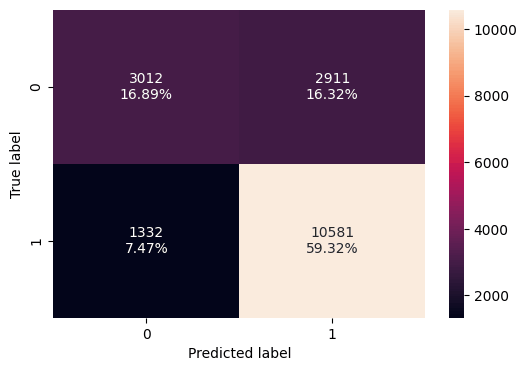

In [337]:
confusion_matrix_sklearn(xgb_tuned, X_train, y_train)

In [338]:
xgb_tuned_model_perf_train = model_performance_classification_sklearn(xgb_tuned, X_train, y_train)
print('Train Performance \n' ,xgb_tuned_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0   0.76211  0.888189   0.784243  0.832986


####Checking the model performance on test set

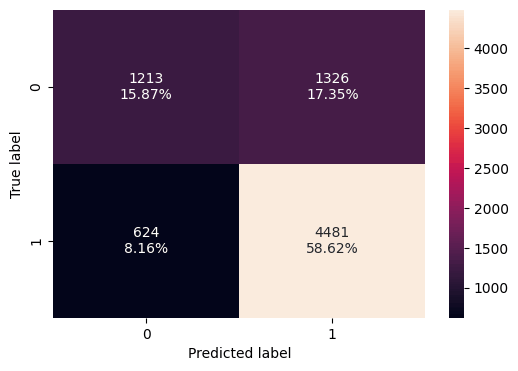

In [339]:
confusion_matrix_sklearn(xgb_tuned, X_test, y_test)

In [340]:
xgb_tuned_model_perf_test = model_performance_classification_sklearn(xgb_tuned, X_test, y_test)
print('Test Performance \n' ,xgb_tuned_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision        F1
0  0.744898  0.877767   0.771655  0.821298


- The overfitting is reduced after hyperparameter tuning, with comparable performance between the train and test performance.
  - The model is showing improved generalization and is no longer overfitting.
- The F1 Metric has also improved from default parameters 0.81 to hyperparameter tuned 0.82 increasing by ~.01

##Stacking Classifier

We will now build a stacking model with a few of the better performing models: Random Forest Tuned, AdaBoost Classifier and Gradient Boosting Tuned, then use XGBoost to get the final prediction.

###Building Model - Stacking Classifier

In [341]:
estimators = [
    ('Random Forest Tuned', rf_tuned),
    ('AdaBoost', ab_classifier),
    ('Gradient Boosting Tuned', gb_tuned)

]
final_estimator = xgb_tuned



In [342]:
stacking_classifier= StackingClassifier(estimators= estimators, final_estimator=final_estimator, cv=5)
stacking_classifier.fit(X_train, y_train)

StackingClassifier(cv=5,
                   estimators=[('Random Forest Tuned',
                                RandomForestClassifier(max_depth=10,
                                                       min_samples_split=7,
                                                       n_estimators=20,
                                                       oob_score=True,
                                                       random_state=1)),
                               ('AdaBoost', AdaBoostClassifier(random_state=1)),
                               ('Gradient Boosting Tuned',
                                GradientBoostingClassifier(learning_rate=0.05,
                                                           max_features=0.8,
                                                           random_state=1,
                                                           subsample=0.9))],
                   final_estimator=XGBCl...
                                                 feature_types=None, gamma=3,
                                                 grow_policy=None,
                                                 importance_type=None,
                                                 interaction_constraints=None,
                                                 learning_rate=0.05,
                                                 max_bin=None,
                                                 max_cat_threshold=None,
                                                 max_cat_to_onehot=None,
                                                 max_delta_step=None,
                                                 max_depth=None,
                                                 max_leaves=None,
                                                 min_child_weight=None,
                                                 missing=nan,
                                                 monotone_constraints=None,
                                                 multi_strategy=None,
                                                 n_estimators=50, n_jobs=None,
                                                 num_parallel_tree=None,
                                                 random_state=1, ...))

####Checking the model performance on training set

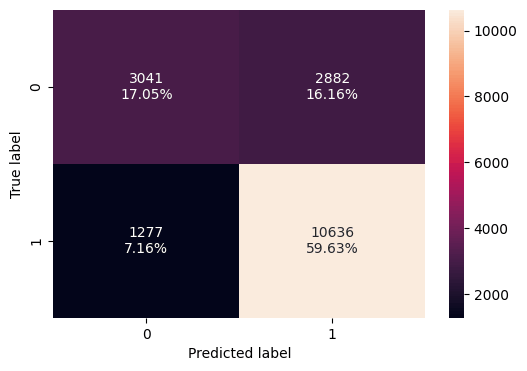

In [343]:
confusion_matrix_sklearn(stacking_classifier, X_train, y_train)

In [344]:
stacking_classifier_model_perf_train = model_performance_classification_sklearn(stacking_classifier, X_train, y_train)
print('Train Performance \n' ,stacking_classifier_model_perf_train)

Train Performance 
    Accuracy    Recall  Precision        F1
0   0.76682  0.892806   0.786803  0.836459


####Checking the model performance on test set

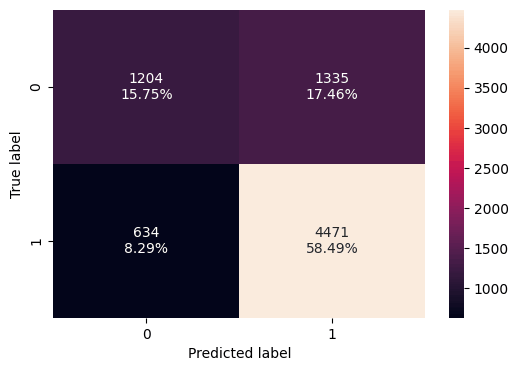

In [345]:
confusion_matrix_sklearn(stacking_classifier, X_test, y_test)

In [346]:
stacking_classifier_model_perf_test = model_performance_classification_sklearn(stacking_classifier, X_test, y_test)
print('Test Performance \n' ,stacking_classifier_model_perf_test)

Test Performance 
    Accuracy    Recall  Precision       F1
0  0.742412  0.875808   0.770065  0.81954


- The Gradient Boost Classifier Model with default parameters is performing well on the training set with relatively comparable performance on the test set.
  - The model is showing good generalization and is slightly overfitting, however the difference is not enough to confidently state it is over fitting.
- The F1 on the test set is 0.82 compared to the train set F1 score of 0.84

## Model Performance Comparison and Conclusions

###Performance Comparison on Training Set of All Models

In [347]:
#comparison of training performance on all models

models_train_comp_df = pd.concat(
    [
        decision_tree_perf_train.T,
        dtree_classifier_model_perf_train.T,
        bagging_model_perf_train.T,
        bagging_classifier_tuned_model_perf_train.T,
        rf_model_perf_train.T,
        rf_tuned_model_perf_train.T,
        ab_classifier_model_perf_train.T,
        ab_tuned_model_perf_train.T,
        gb_classifier_model_perf_train.T,
        gb_tuned_model_perf_train.T,
        xgb_classifier_model_perf_train.T,
        xgb_tuned_model_perf_train.T,
        stacking_classifier_model_perf_train.T,

      ],
    axis=1,
)

models_train_comp_df.columns= [
    'Decision Tree',
    'Decision Tree Tuned',
    'Bagging Classifier',
    'Bagging Classifier Tuned',
    'Random Forest',
    'Random Forest Tuned',
    'AdaBoost Classifier',
    'AdaBoost Classifier Tuned',
    'Gradient Boost Classifier',
    'Gradient Boost Classifier Tuned',
    'XGBoost Classifier',
    'XGBoost Classifier Tuned',
    'Stacking Classifier',
]

print('Training Performance Comparison')
models_train_comp_df

Training Performance Comparison


,Decision Tree,Decision Tree Tuned,Bagging Classifier,Bagging Classifier Tuned,Random Forest,Random Forest Tuned,AdaBoost Classifier,AdaBoost Classifier Tuned,Gradient Boost Classifier,Gradient Boost Classifier Tuned,XGBoost Classifier,XGBoost Classifier Tuned,Stacking Classifier
Accuracy,1.0,0.712548,0.985198,0.996187,0.999944,0.769119,0.738226,0.738562,0.758802,0.754766,0.850807,0.762110,0.766820
Recall,1.0,0.931923,0.985982,0.999916,0.999916,0.918660,0.887182,0.890876,0.883740,0.885671,0.935952,0.888189,0.892806
Precision,1.0,0.720067,0.991810,0.994407,1.000000,0.776556,0.760688,0.759373,0.783042,0.777925,0.854537,0.784243,0.786803
F1,1.0,0.812411,0.988887,0.997154,0.999958,0.841652,0.819080,0.819885,0.830349,0.828309,0.893394,0.832986,0.836459


###Performance Comparison on Test Set of All Models

In [348]:
#comparison of test performance on all models

models_test_comp_df = pd.concat(
    [
        decision_tree_perf_test.T,
        dtree_classifier_model_perf_test.T,
        bagging_model_perf_test.T,
        bagging_classifier_tuned_model_perf_test.T,
        rf_model_perf_test.T,
        rf_tuned_model_perf_test.T,
        ab_classifier_model_perf_test.T,
        ab_tuned_model_perf_test.T,
        gb_classifier_model_perf_test.T,
        gb_tuned_model_perf_test.T,
        xgb_classifier_model_perf_test.T,
        xgb_tuned_model_perf_test.T,
        stacking_classifier_model_perf_test.T,

      ],
    axis=1,
)

models_test_comp_df.columns= [
    'Decision Tree',
    'Decision Tree Tuned',
    'Bagging Classifier',
    'Bagging Classifier Tuned',
    'Random Forest',
    'Random Forest Tuned',
    'AdaBoost Classifier',
    'AdaBoost Classifier Tuned',
    'Gradient Boost Classifier',
    'Gradient Boost Classifier Tuned',
    'XGBoost Classifier',
    'XGBoost Classifier Tuned',
    'Stacking Classifier',
]

print('Test Performance Comparison')
models_test_comp_df

Test Performance Comparison


,Decision Tree,Decision Tree Tuned,Bagging Classifier,Bagging Classifier Tuned,Random Forest,Random Forest Tuned,AdaBoost Classifier,AdaBoost Classifier Tuned,Gradient Boost Classifier,Gradient Boost Classifier Tuned,XGBoost Classifier,XGBoost Classifier Tuned,Stacking Classifier
Accuracy,0.664835,0.706567,0.691523,0.724228,0.720827,0.738095,0.734301,0.733255,0.744767,0.742543,0.729984,0.744898,0.742412
Recall,0.742801,0.930852,0.764153,0.895397,0.832125,0.898923,0.885015,0.887365,0.876004,0.878550,0.851518,0.877767,0.875808
Precision,0.752232,0.715447,0.771711,0.743857,0.768869,0.755391,0.757799,0.755756,0.772366,0.768901,0.768972,0.771655,0.770065
F1,0.747487,0.809058,0.767913,0.812622,0.799247,0.820930,0.816481,0.816290,0.820927,0.820077,0.808143,0.821298,0.819540


###Final Model Selection
- The Gradient Boost Classifier Model is the best model when compared to the others. Among all models it combines both very good generalization evidenced by difference between train and test performance across all metrics, while having among the highest F1 Scores at approximately 0.821

- The XGBoost Tuned and Random Forest Tuned Models are also good candidates having marginally higher F1 scores. However, the difference between train and test metrics is slightly larger showing a bit less apptitude for generalization.





Feature Importances of Final Model

In [349]:
print(pd.DataFrame(gb_classifier.feature_importances_, columns = ["Imp"], index = X_train.columns).sort_values(by = 'Imp', ascending = False))

                                        Imp
education_of_employee_High School  0.285978
has_job_experience_Y               0.155462
prevailing_wage                    0.136663
education_of_employee_Master's     0.087565
education_of_employee_Doctorate    0.083538
continent_Europe                   0.063035
unit_of_wage_Year                  0.036526
region_of_employment_Midwest       0.034432
region_of_employment_South         0.019024
no_of_employees                    0.014866
continent_North America            0.014537
yr_of_estab                        0.014220
region_of_employment_West          0.013583
continent_Asia                     0.011354
full_time_position_Y               0.009000
region_of_employment_Northeast     0.008039
continent_South America            0.007043
requires_job_training_Y            0.004692
continent_Oceania                  0.000311
unit_of_wage_Month                 0.000133
unit_of_wage_Week                  0.000000


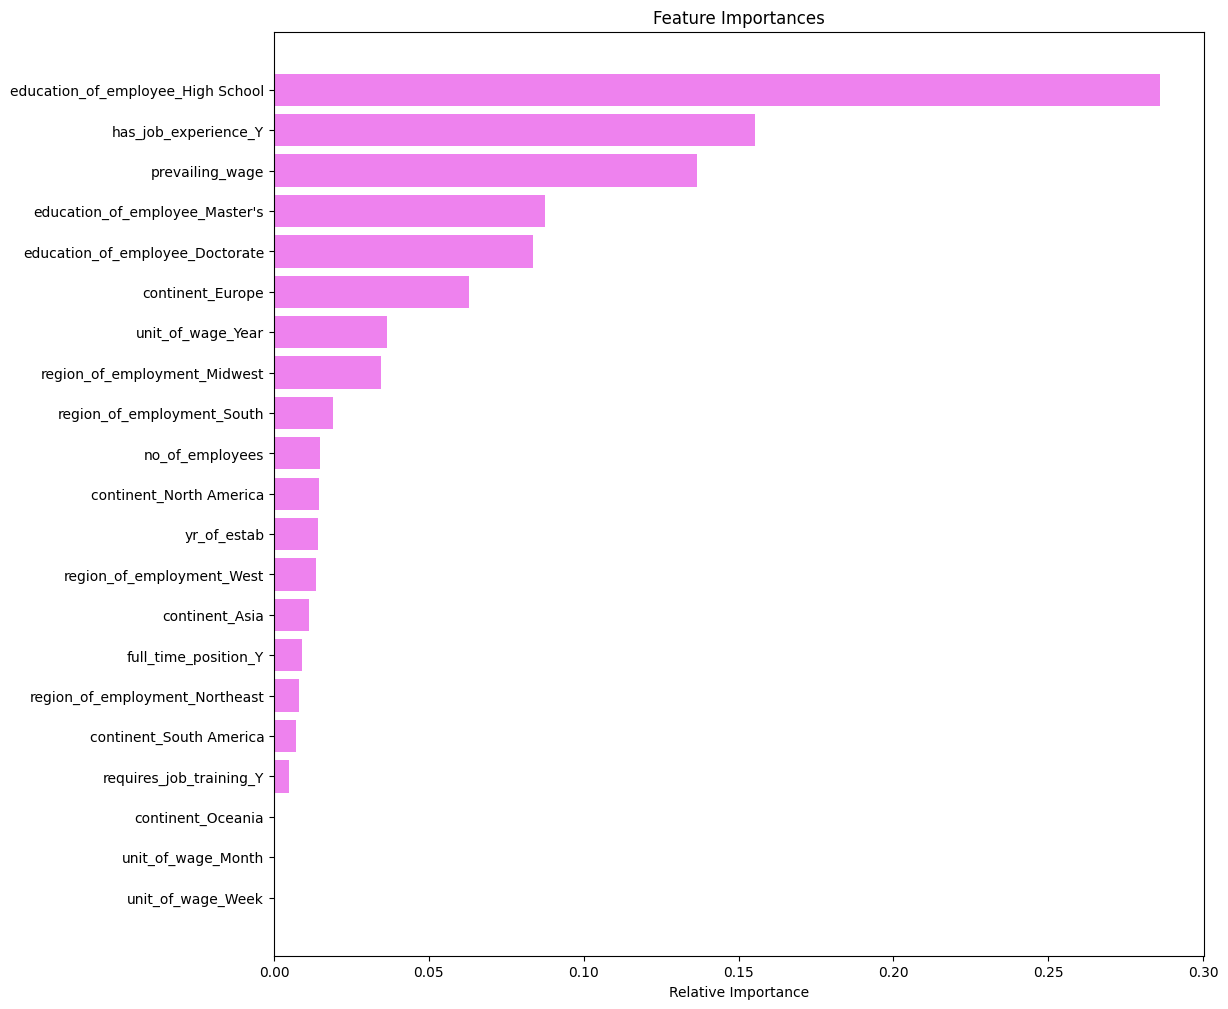

In [350]:
feature_names = X_train.columns
importances = gb_classifier.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(12,12))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], color='violet', align='center')
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()

- The most important features considered in the final model are education_of employee_high_school, followed by has_job_experience_Y and prevailing wage.

## Actionable Insights and Recommendations

- We have been able to build a predictive model to aid in processing the increasing number of visa applicants.
  - The model can be deployed to save time and resources when considering the increasing number of applications year over year.

- By pre-screening visa applications with the model, more qualified applicants can be considered for positions they are deserving of.
  - Some applicants who may not have been considered due to the sheer volume and time to process applicants will have the opportunity to be considered when in the past their applications may have never been reviewed due to limited time and resources dedicated towards processing applications.

- Factors that drive the case status of a visa application - Education of Employee High School, Has Job Experience and prevailing wage.

- Sample profile of a certified visa:

An application where the education level is not high school level, where the applicant has previous job experience, a higher prevailing wage (meaning the wage type is likely not hourly), has higher levels of education such as a masters or a doctorate, with the originating continent is Europe, the unit of wage for the job is yearly and their region of employment is in the Midwest or the South will most likely have their Visa application certified.


- The OFLC should spend less time focusing on lower education level employees who are applying for hourly positions with no previous job experience and are applying from either Oceania or South America as they are less likely to have their Visa applications approved.

- We should continue to gather information year over year to improve and refine the model







